In [1]:
import numpy as np
import torch
import os
import matplotlib.pyplot as plt
# from src.steinbrinker.BPDN import BPDN
import timeit
import mlflow
import sys
import pylops
from tqdm import tqdm

PROJECT_PATH = 'C:\\Users\\galig\\Desktop\\ecg-denoising\\workspace'
PROJECT_SRC_PATH = os.path.join(PROJECT_PATH, 'src\\refactored')

sys.path.append(PROJECT_SRC_PATH)

from src.trainers.FISTANetTrainer import FISTANetTrainer
from src.trainers.CNNTrainer import CNNTrainer
from src.utils.loader import DataSplit

plt.rcParams["figure.figsize"] = (12, 7)
plt.rcParams["figure.dpi"] = 300

# avoid type-3 fonts
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

In [2]:
DATA_DIR = './data'
DATA_FILE_GEN = 'generated/BW_master_10000_2024-04-07-12-43-32.pkl'
DATA_FILE_SIGS = 'steinbrinker/testing_data_mvg_avg.npy'
DATA_FILE_BW = 'mit-bih/bw'
DATA_FILE_GAUSS = 'generated/gaussian_noise.npy'
DATA_FILE_BPDN_1 = 'generated/BW_alphas-BPDN-1iters_10000_2024-04-07-12-43-32.npy'
DATA_FILE_BPDN_3 = 'generated/BW_alphas-BPDN-3iters_10000_2024-04-07-12-43-32.npy'
DATA_FILE_BPDN_5 = 'generated/BW_alphas-BPDN-5iters_10000_2024-04-07-12-43-32.npy'
DATA_FILE_BPDN_FINAL = 'generated/BW_alphas-BPDN_10000_2024-04-07-12-43-32.npy'
DICT_FILE_BW = 'steinbrinker/dictionary_BW_real_data.npy'
NOISE_TYPE = 'bw'
if NOISE_TYPE == 'bw':
    DATA_FILE_NOISE = DATA_FILE_BW
elif NOISE_TYPE == 'gauss':
    DATA_FILE_NOISE = DATA_FILE_GAUSS
DATA_SIZE = 10000
BATCH_SIZE = 1000
TVT_SPLIT = {
    'train': 80,
    'valid': 10,
    'test': 10
}

RUN_ID = 'a7f7899e0ad043c68319cea0e6a7d548'

mlflow.set_tracking_uri('http://localhost:8080')

In [3]:
trn_ldr, val_ldr, tst_ldr = DataSplit(DATA_DIR, NOISE_TYPE, DATA_FILE_GEN, DATA_FILE_SIGS, DATA_FILE_NOISE, DATA_FILE_BPDN_1,
                                      DATA_FILE_BPDN_FINAL, TVT_SPLIT, BATCH_SIZE)

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dict_np = np.load(os.path.join(DATA_DIR, DICT_FILE_BW))
dictionary = torch.from_numpy(dict_np)
dictionary = dictionary.clone().detach().to(device=device)
dictionary = dictionary.repeat((next(iter(tst_ldr))[0].shape[0], 1, 1))

In [5]:
params = mlflow.get_run(RUN_ID).data.params
params = {
    'batch_size': int(params['batch_size']),
    'device': params['device'],
    'fnet_feature_no': int(params['fnet_feature_no']),
    'fnet_layer_no': int(params['fnet_layer_no']),
    'lambda_pred_sp_loss': int(params['lambda_pred_sp_loss']),
    'lambda_sp_loss': float(params['lambda_sp_loss']),
    'lambda_sym_loss': float(params['lambda_sym_loss']),
    'lr': float(params['lr']),
    'lr_dec_after': int(params['lr_dec_after']),
    'lr_dec_every': int(params['lr_dec_every'])
}
params['load_model_run'] = RUN_ID
params['load_model_epoch'] = 17000

# params = {k: params[k] if k == 'device' else float(params[k]) for k in params.keys()}

loaded_model = mlflow.pytorch.load_model(f'runs:/{RUN_ID}/models/FISTA-Net_ep17000')

Psi = torch.from_numpy(np.load(os.path.join(DATA_DIR, DICT_FILE_BW)))
Psi = Psi.clone().detach().to(device=device)
bpdn_est = np.load(os.path.join(DATA_DIR, DATA_FILE_BPDN_FINAL))
diction = np.load(os.path.join(DATA_DIR, DICT_FILE_BW))

trainer = FISTANetTrainer(loaded_model, Psi, bpdn_est, diction, params)
res = trainer.infer(tst_ldr)

x_fistanet = torch.stack([l[1] for l in res], dim=0).flatten(0, 1).squeeze()

x_fistanet_cut = x_fistanet.clone()
x_fistanet_cut[x_fistanet_cut.abs()<.3] = 0.0

In [6]:
params['load_model_run'] = '9167f4ead13343e89df56bfdc20473e5'
params['load_model_epoch'] = 3000

loaded_model = mlflow.pytorch.load_model(f'runs:/{RUN_ID}/models/FISTA-Net_ep3000')

trainer = CNNTrainer(loaded_model, Psi, bpdn_est, diction, params)

res = trainer.infer(tst_ldr)

denoised_cnn = torch.stack(res, dim=0).flatten(0, 1).squeeze()

In [7]:
def plot_single_signal(signal, color, figname, xlim=[0, 2500], ylim=[-0.5, 2.8], figsize=(13, 4), linewidth=3):
    fig = plt.figure(figsize=figsize, dpi=300)
    plt.plot(signal, color=color, linewidth=linewidth)
    plt.xlim(xlim)
    plt.ylim(ylim)
    plt.xticks([])
    plt.yticks([])
    plt.savefig(f'plots/{figname}.svg')

In [50]:
SIG_LEN = 10          # length of training signals in seconds
SIG_SAMP_RATE = 250   # sampling rate of training signals, i.e. N = second*sampling_Rate
SIG_NO = 500          # number of test signals (>> atom number)

N = SIG_LEN * SIG_SAMP_RATE    # dimension, i.e. atom_number needs to be bigger\n",
x = np.linspace(0, SIG_LEN, N)
half_sig_no = int(SIG_NO//2)
random_shift = np.random.random(half_sig_no) * 2 * SIG_LEN - SIG_LEN
x_shift = x[:, np.newaxis] + random_shift
freqs = np.random.random(half_sig_no) * 0.8   # random frequencies between 0-0.8Hz
train_sigs_sin = np.sin(x_shift * freqs)

In [52]:
train_sigs_sin.shape

(2500, 250)

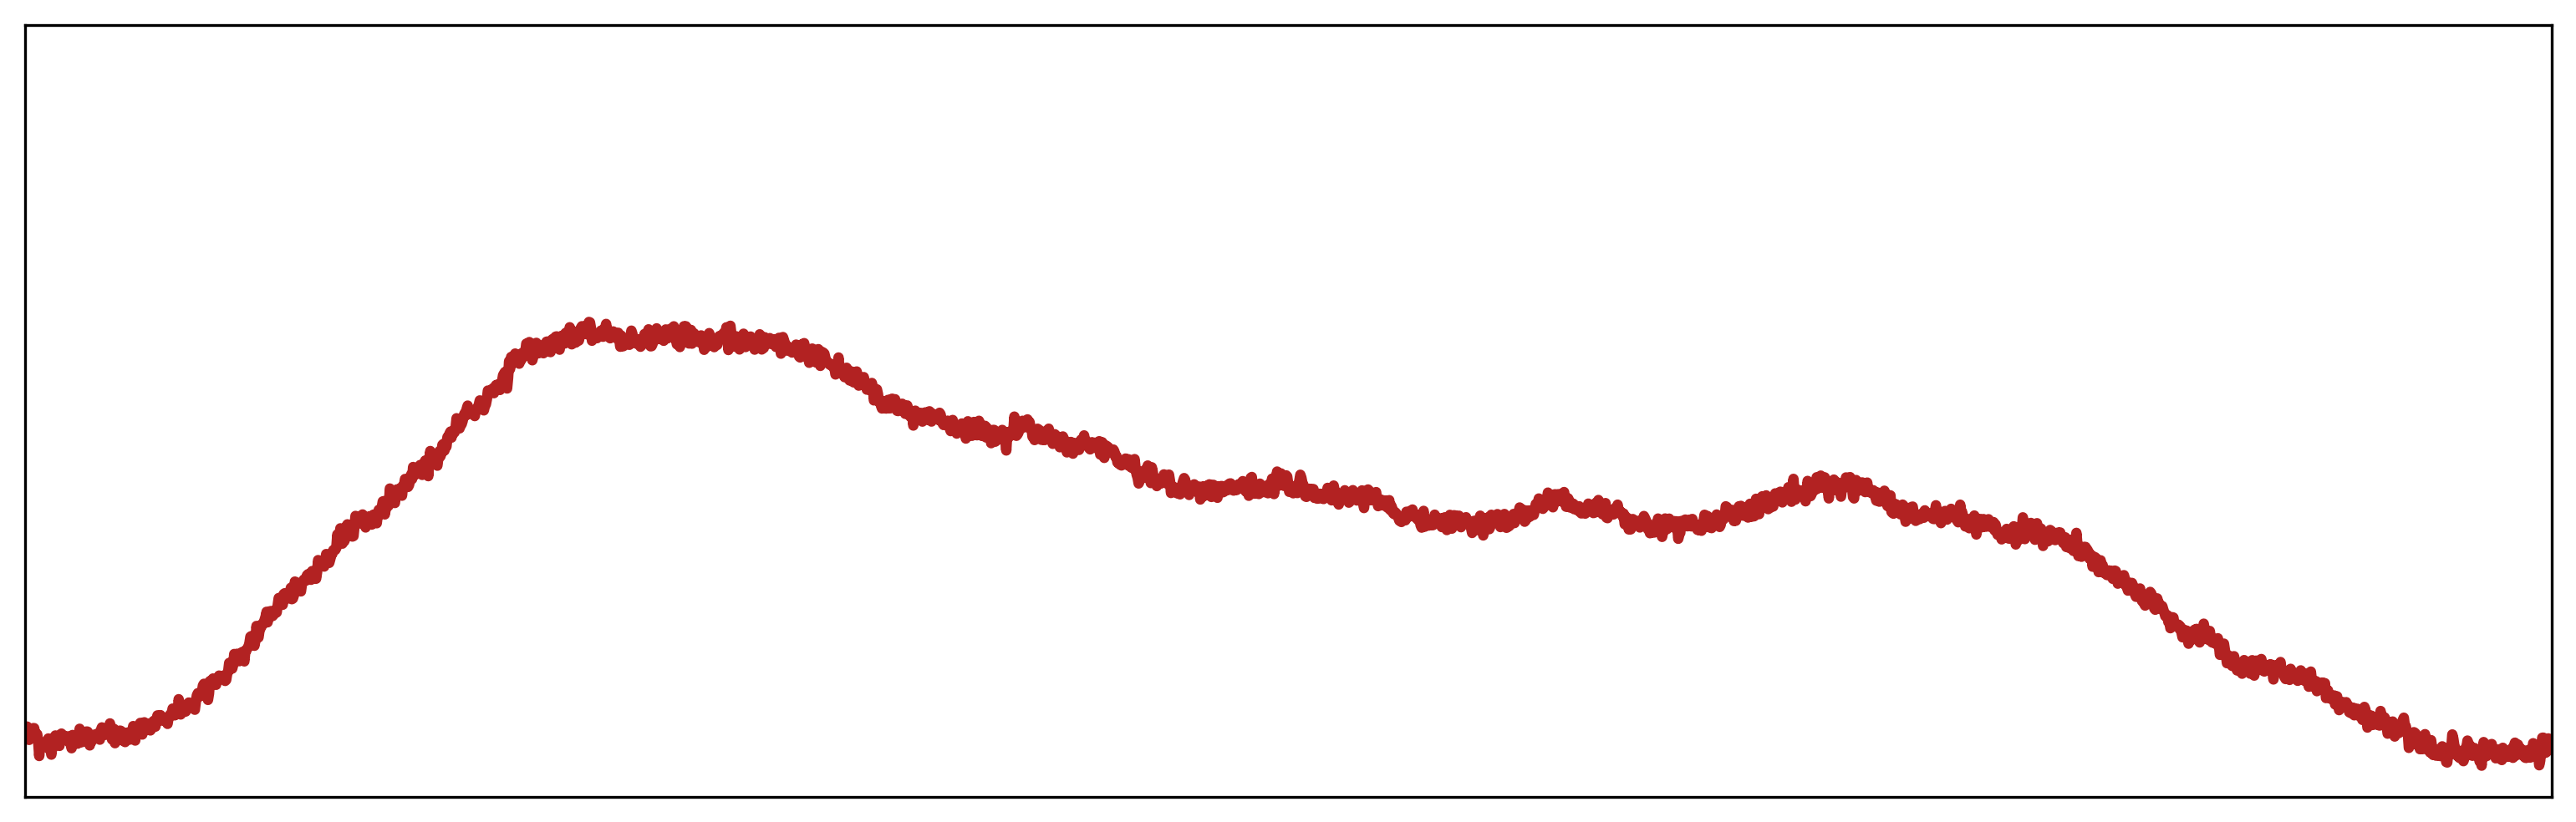

In [62]:
for batch_idy, (b_x_in, b_y_target, b_x_bpdn1, b_x_bpdn, noise) in enumerate(tst_ldr):
    arr_noise = noise[11]
    break
plot_single_signal(arr_noise, 'firebrick', 'x_noise', ylim=[-0.5, 1])

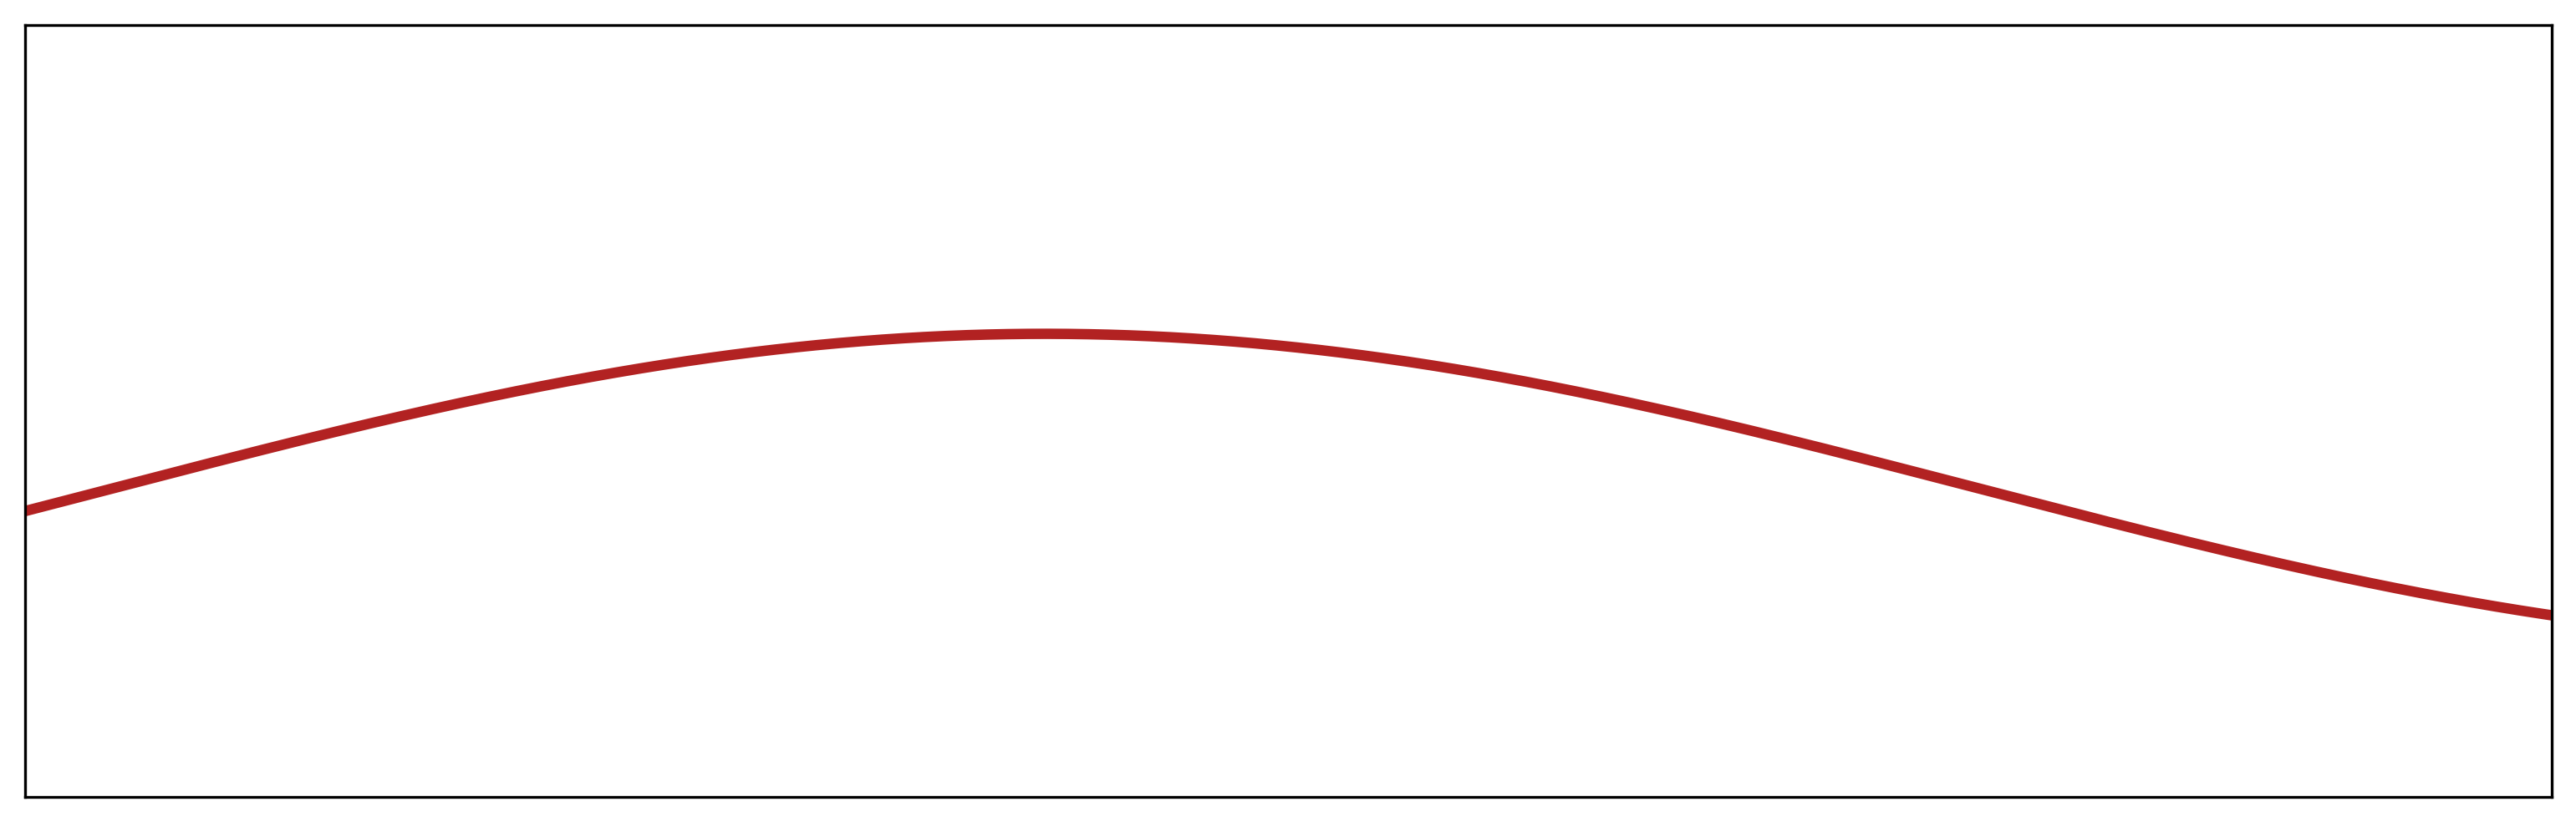

In [63]:
plot_single_signal(train_sigs_sin[:, 0], 'firebrick', 'x_sin', ylim=[-2, 3])

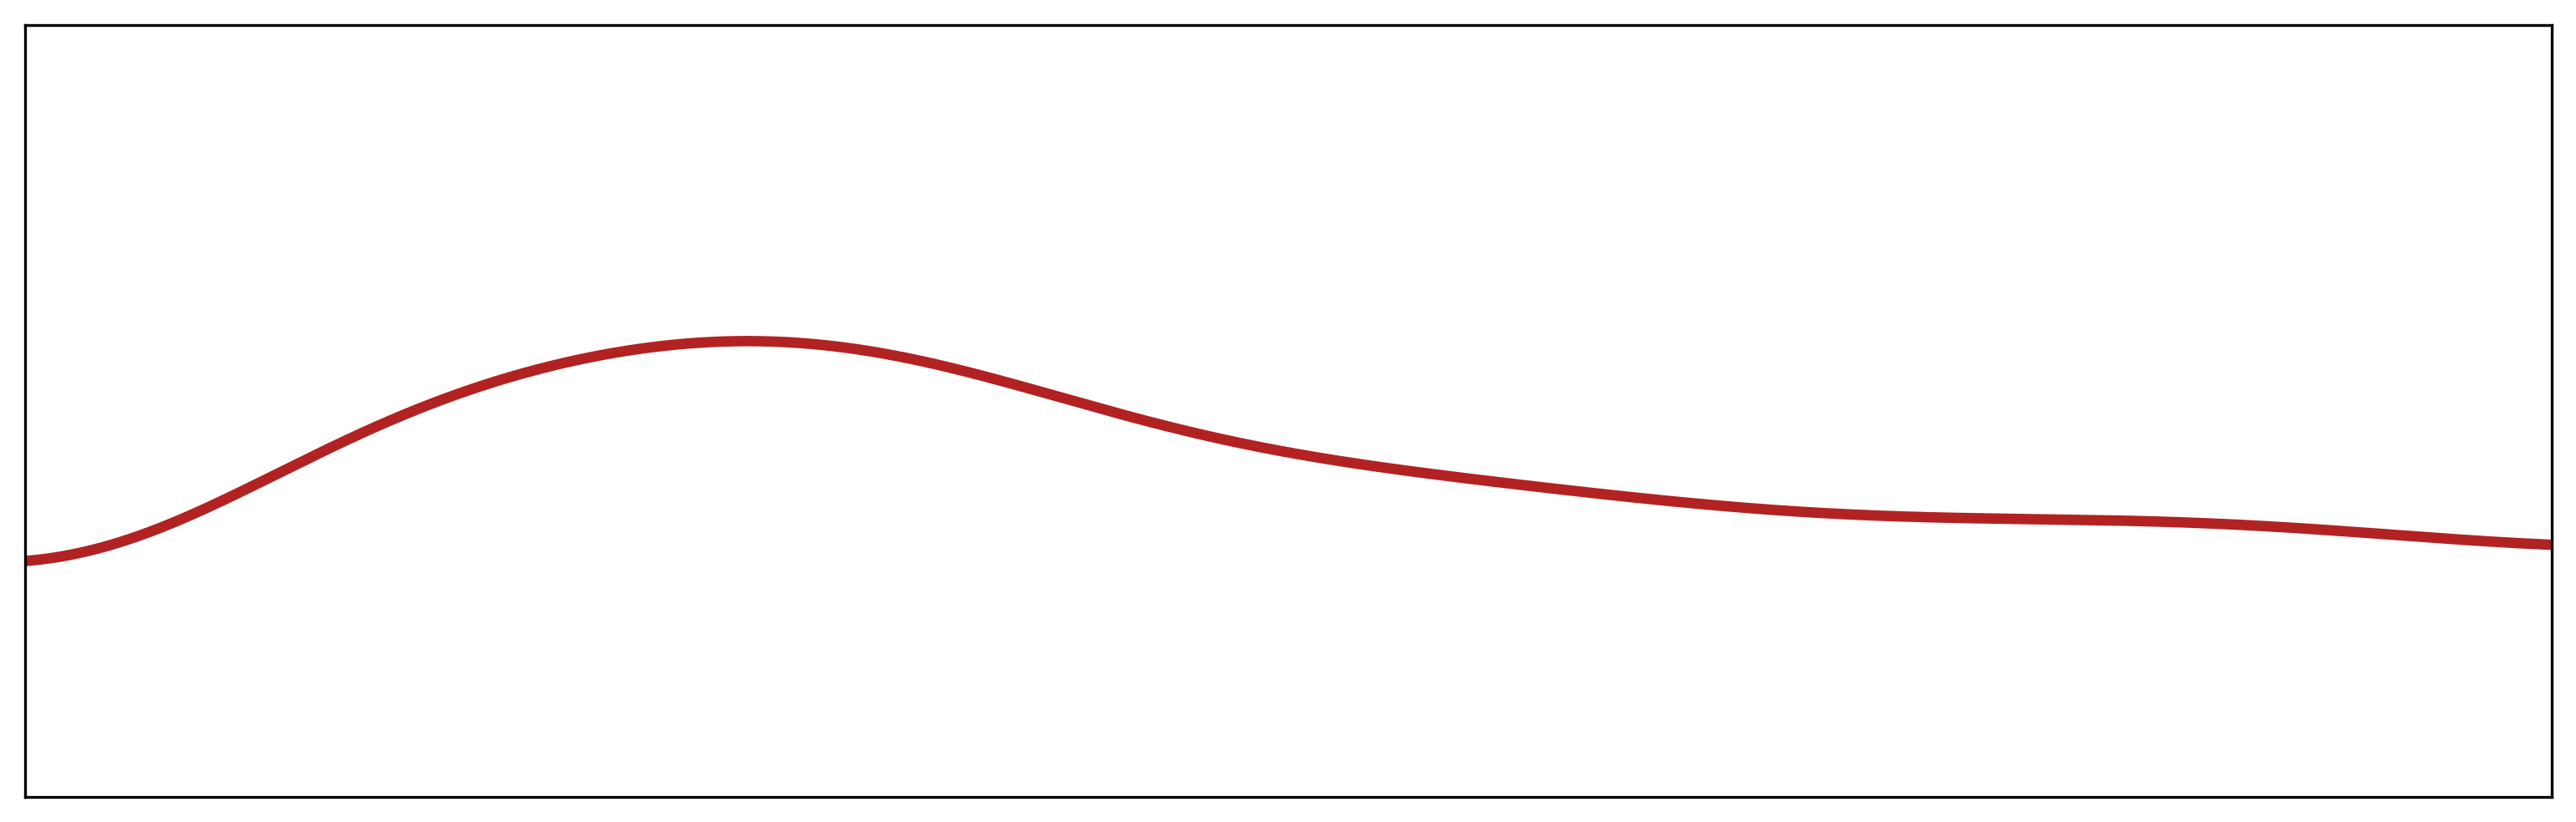

In [64]:
plot_single_signal(dict_np[:, 22], 'firebrick', 'x_dict', ylim=[-0.05, .1])

In [22]:
noise.shape

torch.Size([1000, 2500])

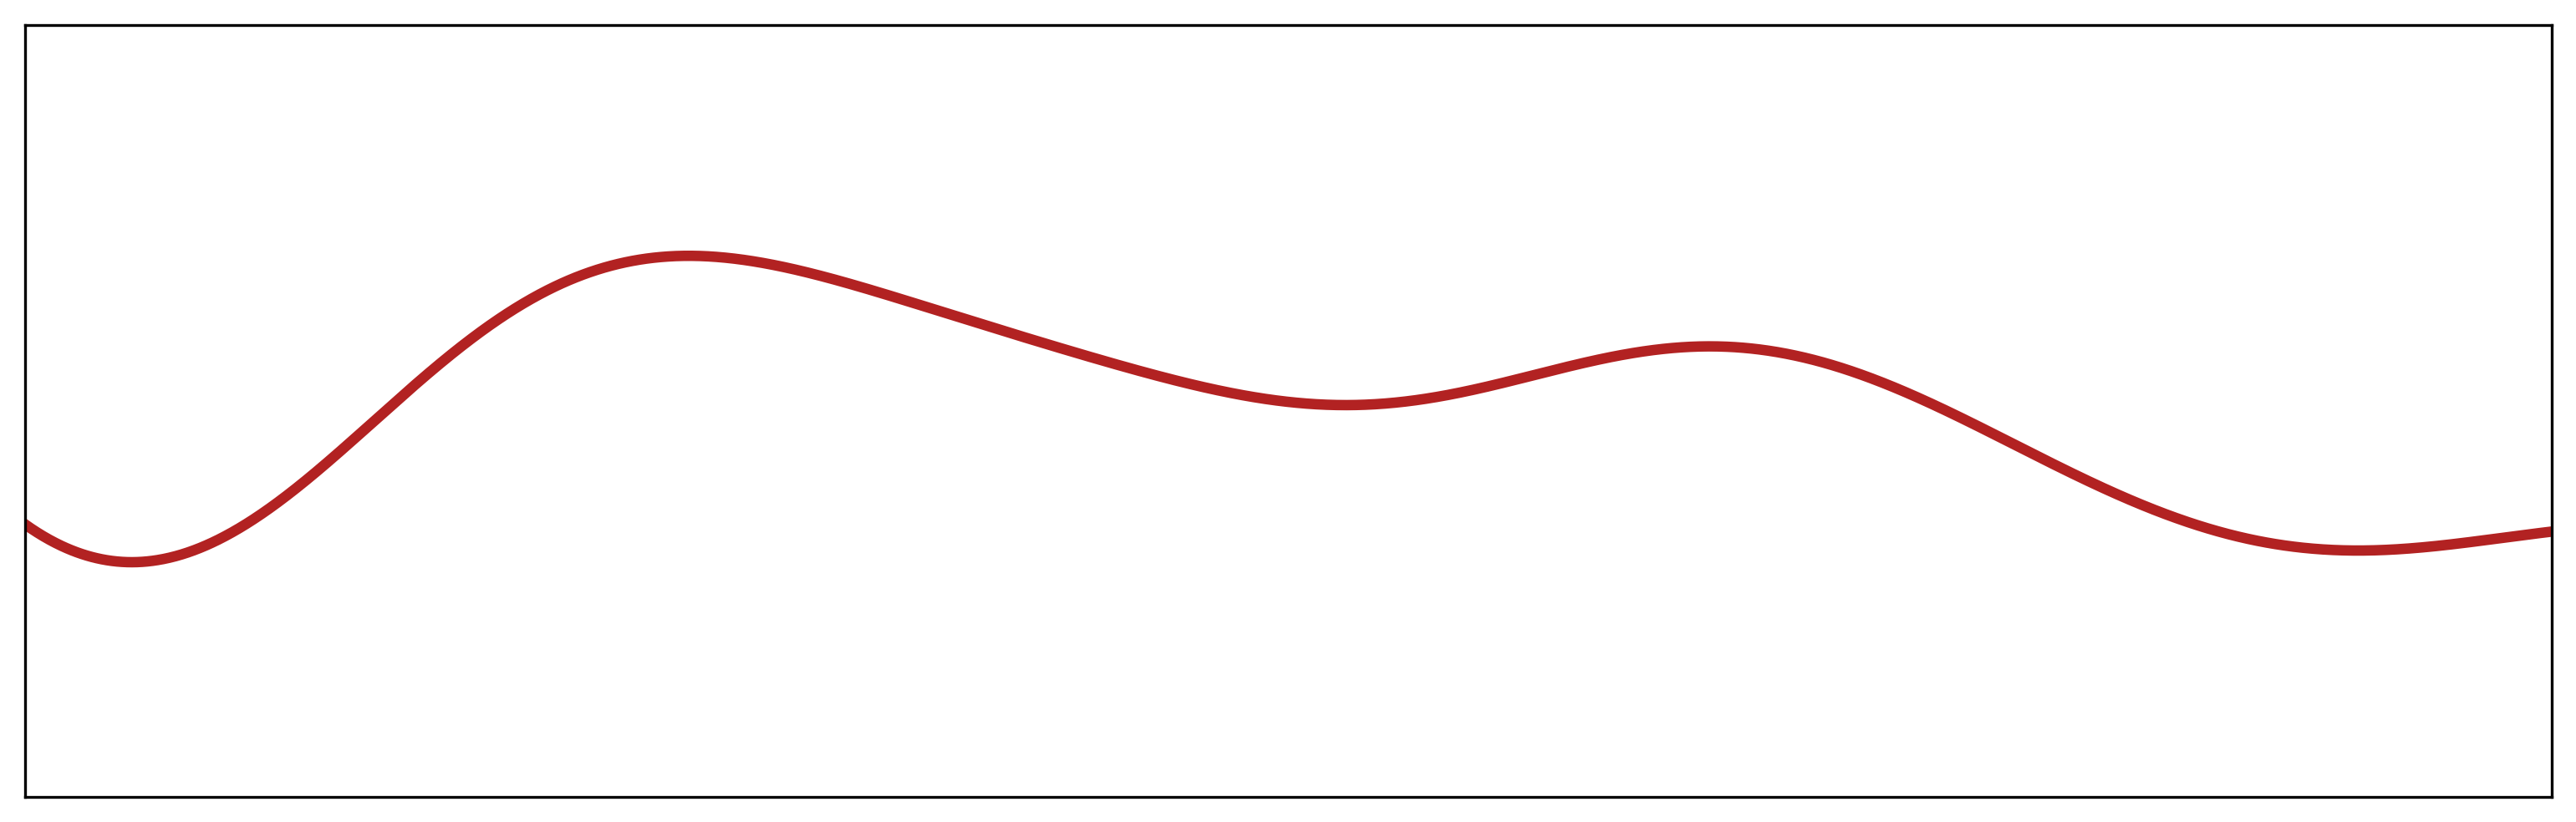

In [27]:
plot_single_signal(noise[11, :].cpu(), 'firebrick', 'x_noise_pred', ylim=[-1, 1])

In [ ]:
plot_single_signal(denoised_fistanet[11].cpu(), 'tab:orange', 'y_hat_fistanet')

In [ ]:
plot_single_signal(x_in[11].cpu(), 'tab:gray', 'x_in_noisy')

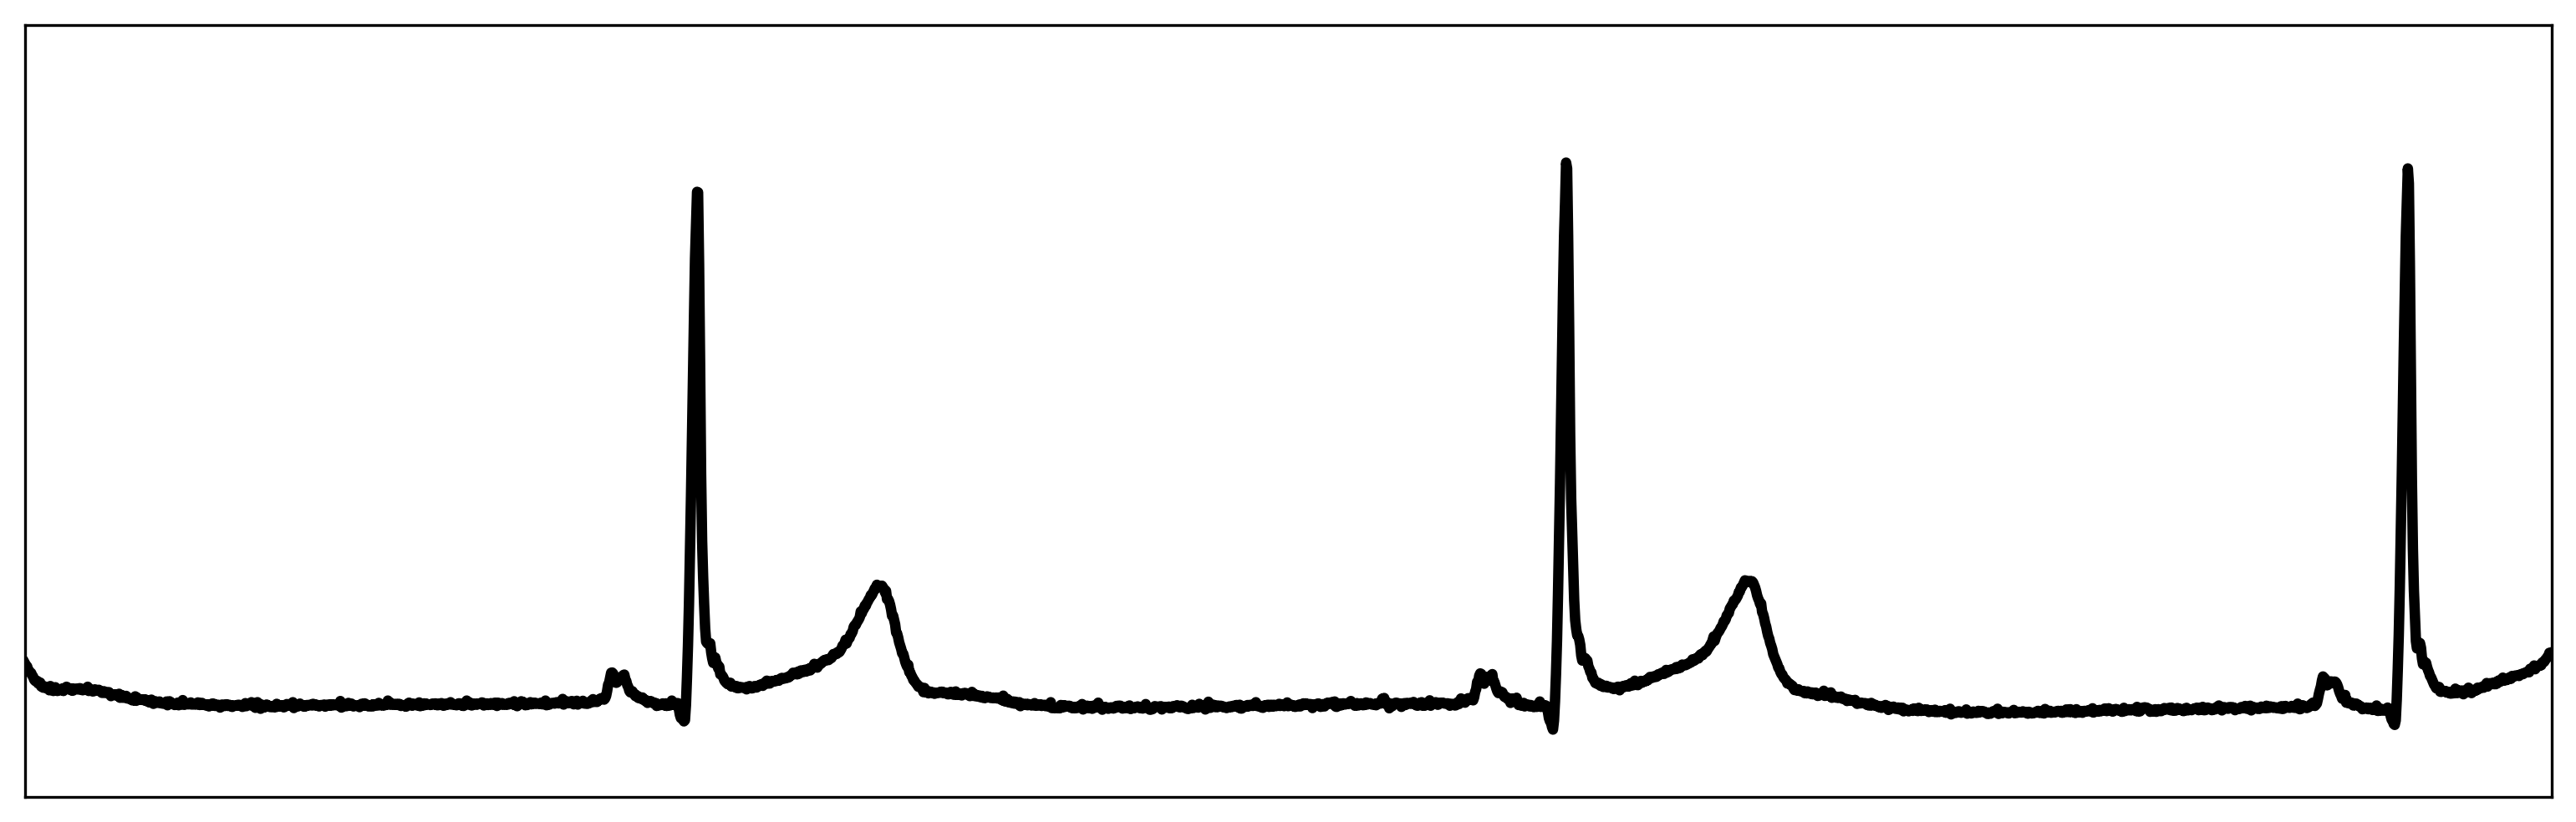

In [16]:
plot_single_signal(y_target[11].cpu(), 'black', 'y_target')

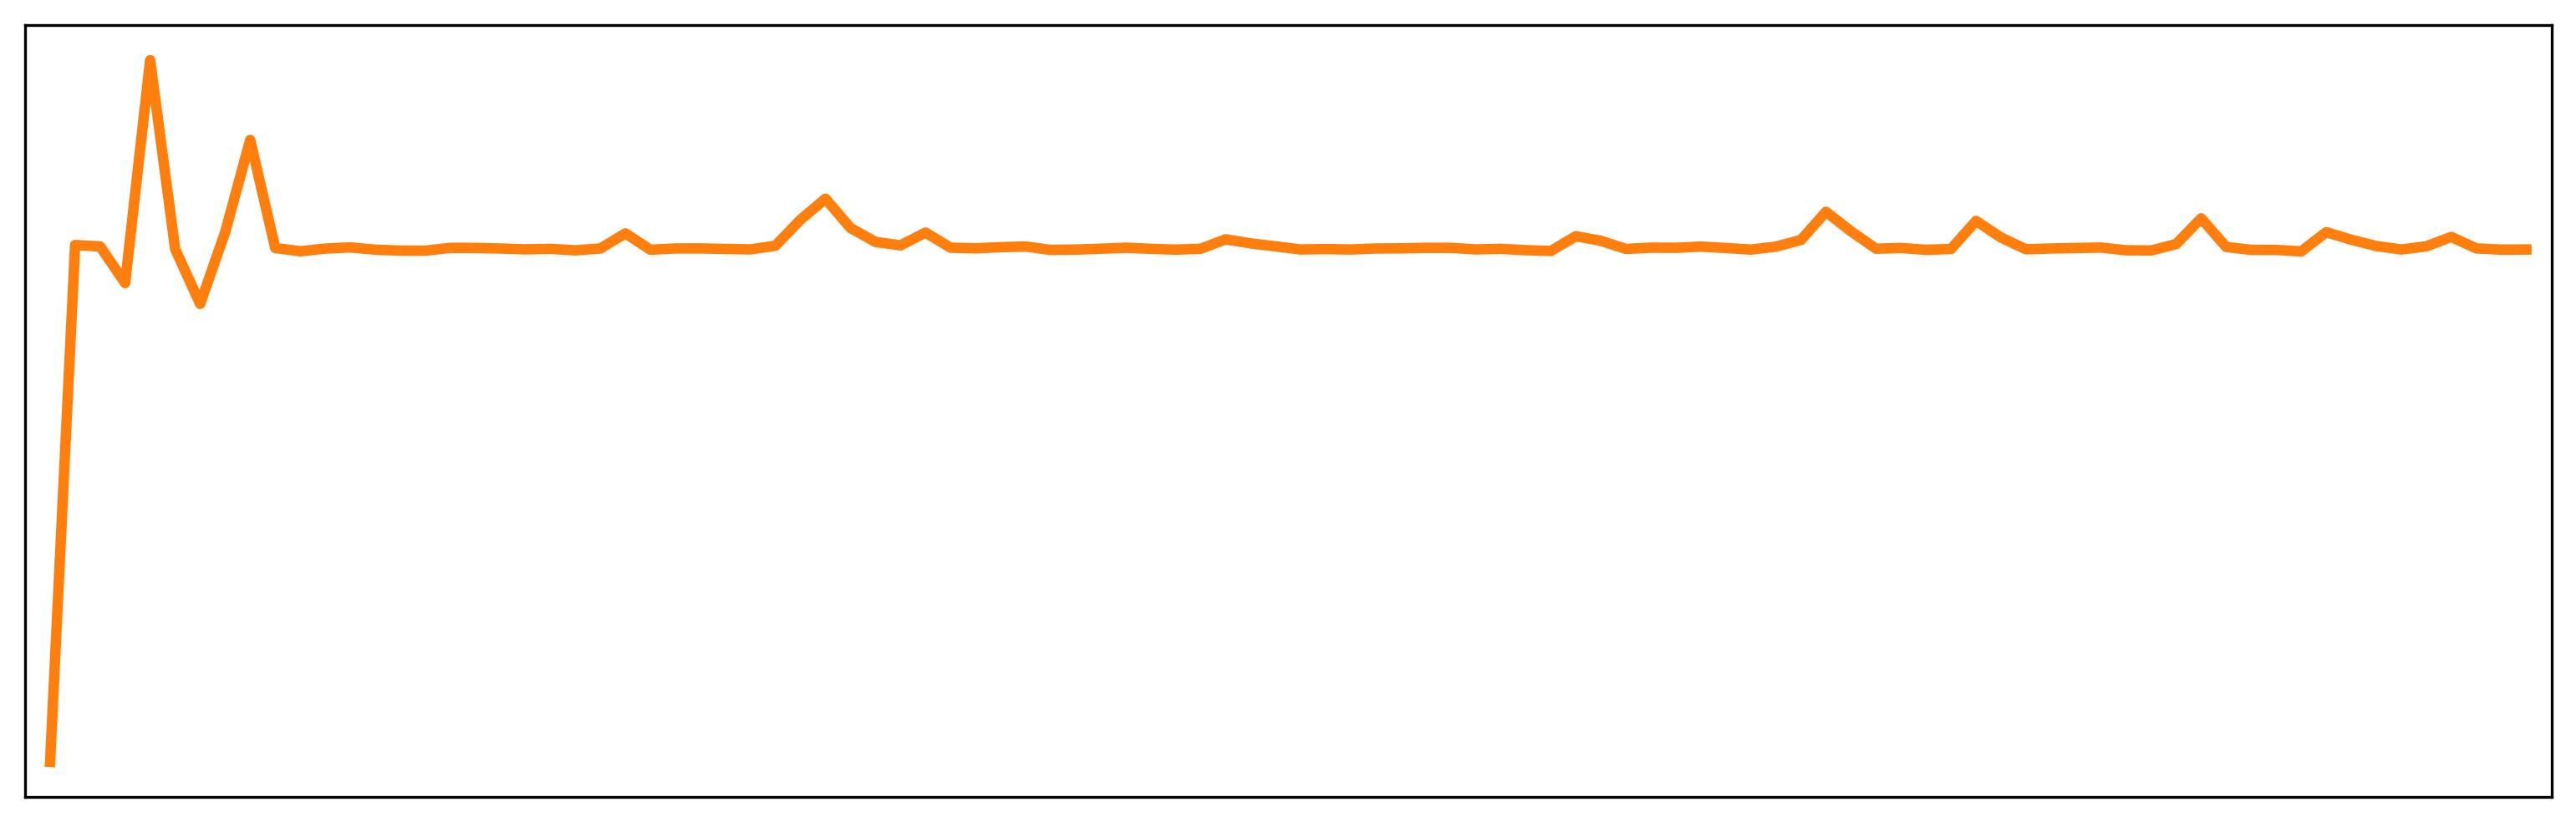

In [17]:
plot_single_signal(x_fistanet[11].cpu(), 'tab:orange', 'x_fistanet', [-1, 100], None)

In [8]:
from matplotlib.pyplot import cycler
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
import matplotlib.cm

def get_cycle(cmap, N=None, use_index="auto"):
    if isinstance(cmap, str):
        if use_index == "auto":
            if cmap in ['Pastel1', 'Pastel2', 'Paired', 'Accent',
                        'Dark2', 'Set1', 'Set2', 'Set3',
                        'tab10', 'tab20', 'tab20b', 'tab20c']:
                use_index=True
            else:
                use_index=False
        cmap = matplotlib.cm.get_cmap(cmap)
    if not N:
        N = cmap.N
    if use_index=="auto":
        if cmap.N > 100:
            use_index=False
        elif isinstance(cmap, LinearSegmentedColormap):
            use_index=False
        elif isinstance(cmap, ListedColormap):
            use_index=True
    if use_index:
        ind = np.arange(int(N)) % cmap.N
        return cycler("color",cmap(ind))
    else:
        colors = cmap(np.linspace(0,1,N))
        return cycler("color",colors)

plt.rcParams["axes.prop_cycle"] = get_cycle("RdBu")

C:\Users\galig\AppData\Local\Temp\ipykernel_12244\2272615796.py:15: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = matplotlib.cm.get_cmap(cmap)


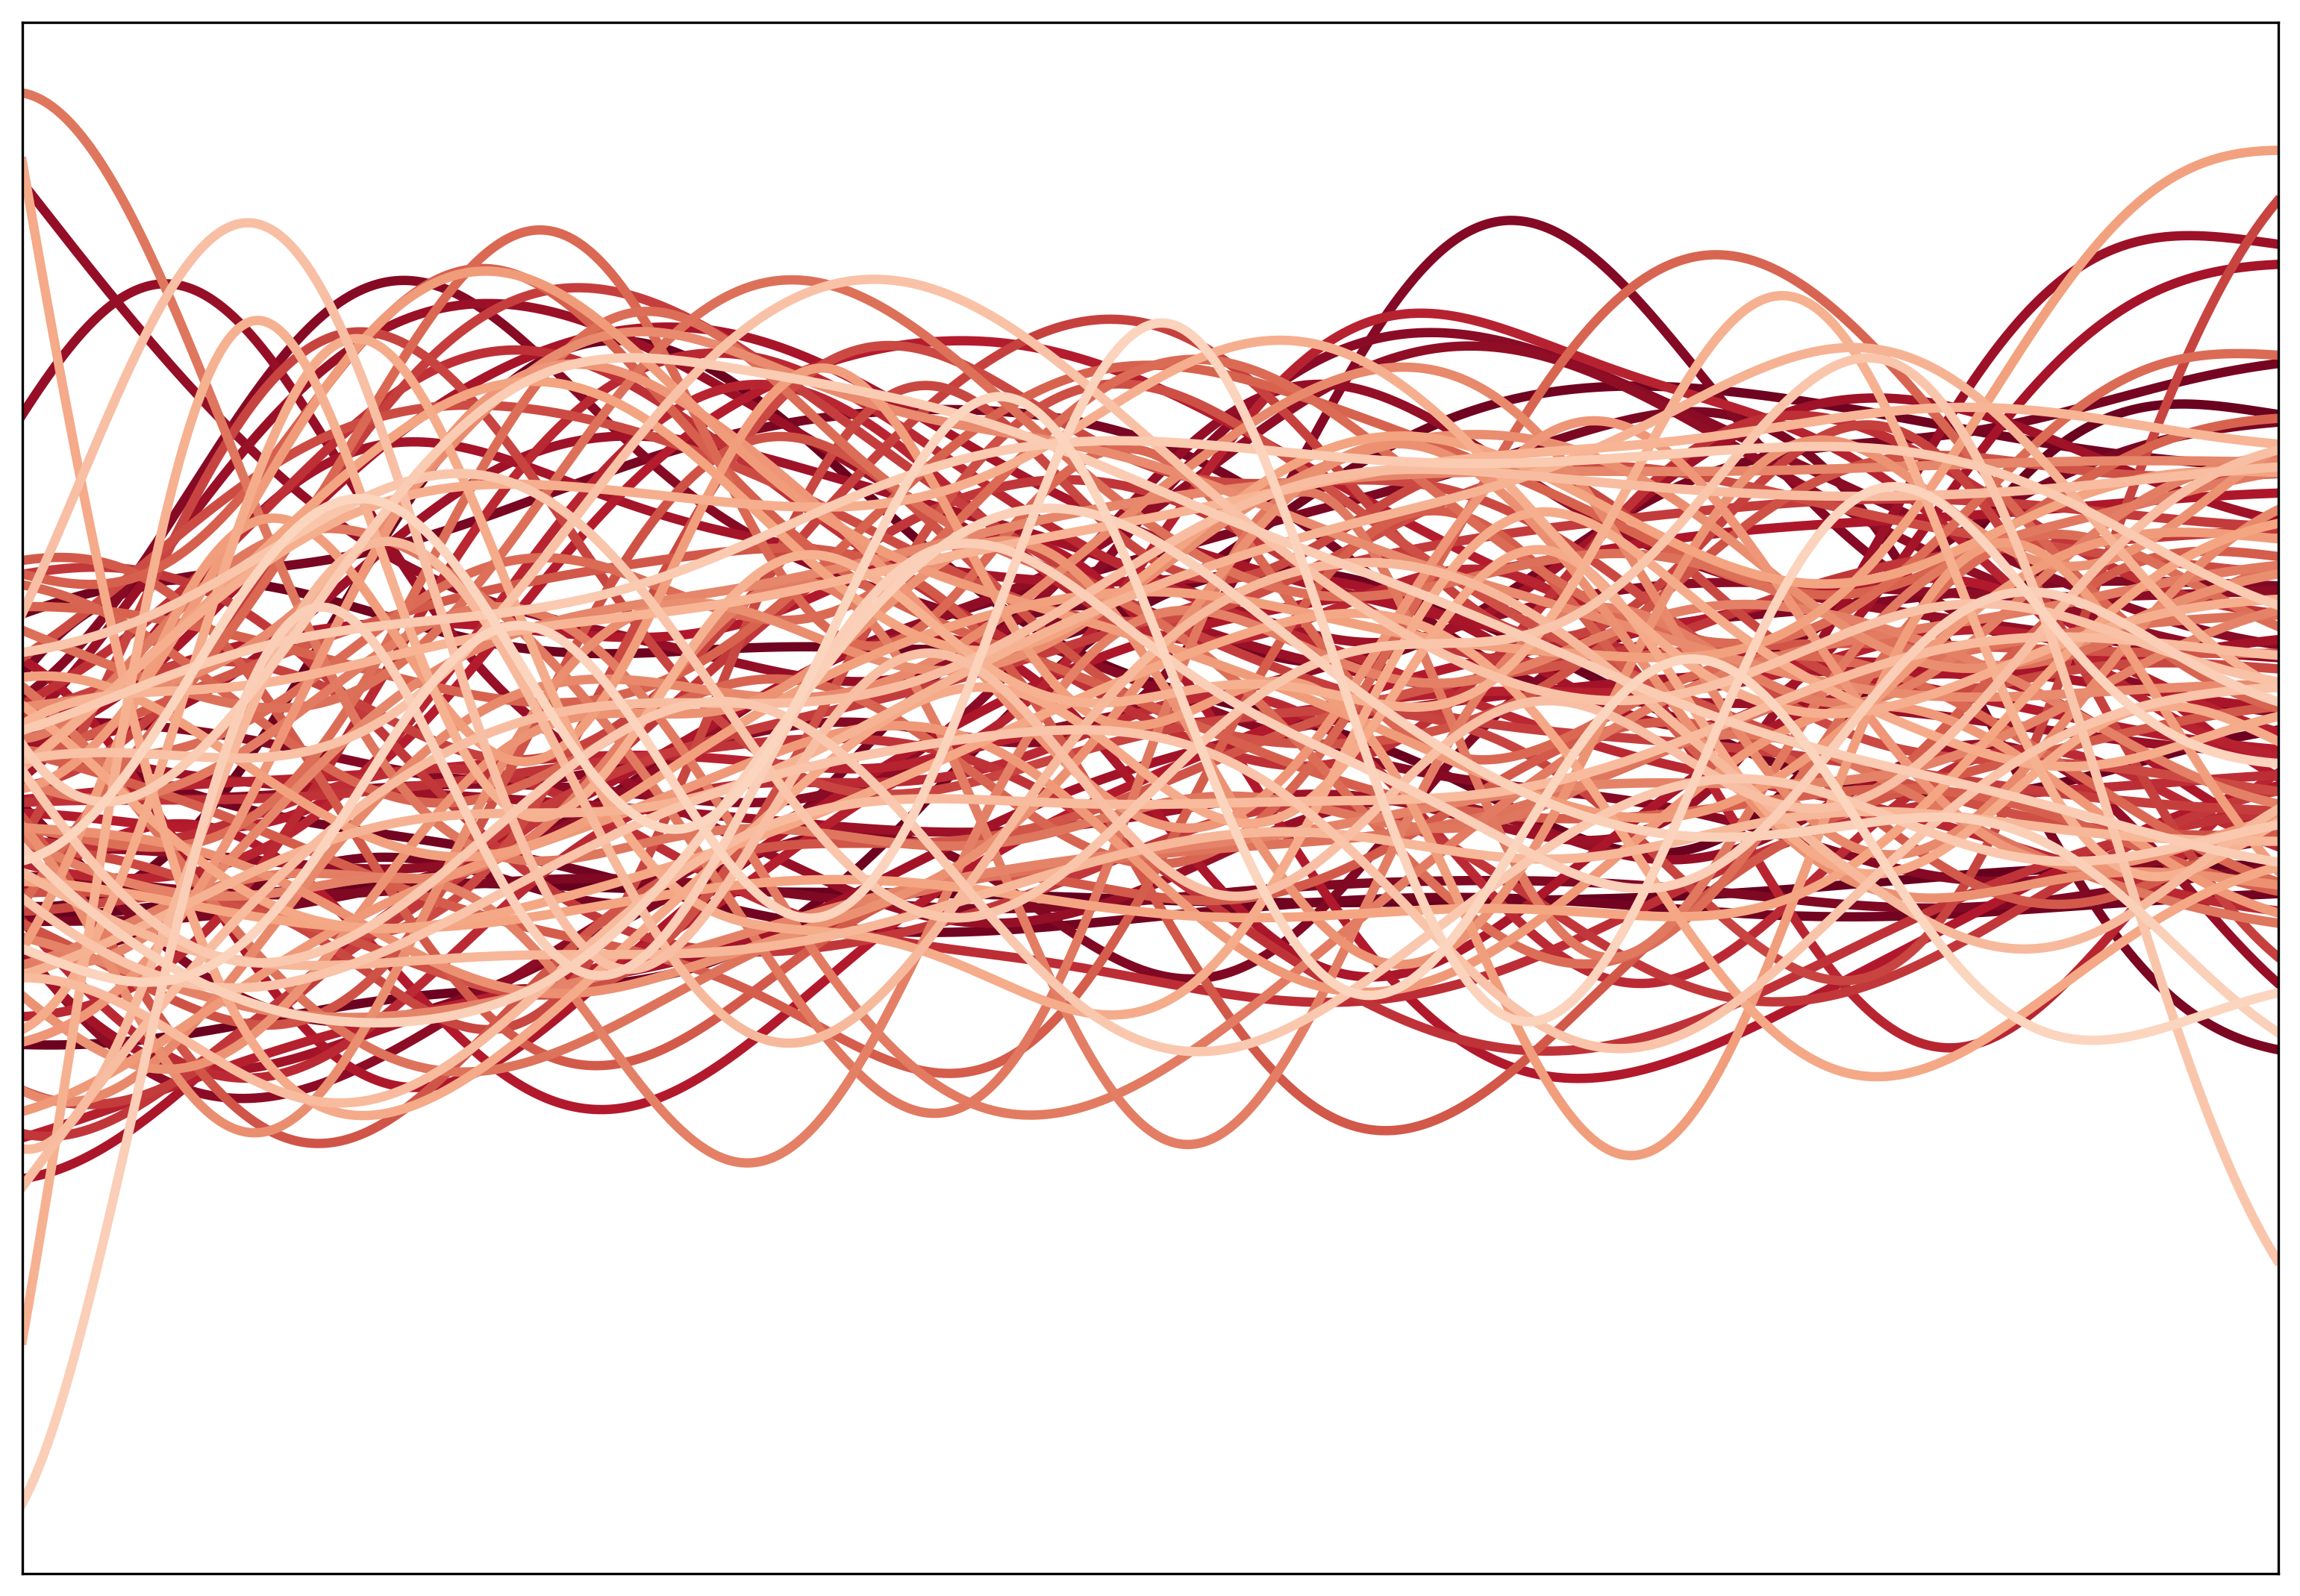

In [19]:
plot_single_signal(dict_np, None, 'dictionary', [0, 2500], None, (13, 9), 3)

In [9]:
def plot_bar_comp(meas_list, y_label, title):
    x = np.arange(len(meas_list.keys()))
    width = 0.5

    fig, ax = plt.subplots(layout='constrained')

    for i, (attribute, measurement) in enumerate(meas_list.items()):
        rects = ax.bar(x[i]+width, measurement, width, label=attribute)
        ax.bar_label(rects, padding=3)

    ax.set_xticks(x + width, meas_list.keys())
    ax.set_ylabel(y_label)
    ax.set_title(title)

    plt.show()

In [10]:
def plot_comp_example_subplt(i, font_size=20):
    global x_in, y_target, denoised_fistanet, denoised_fista, denoised_bpdn, denoised_cnn
    fig, axs = plt.subplots(5, 1, figsize=(11, 11), dpi=300)
    fig.subplots_adjust(0.06, 0.06, 1.0, 1, 0, 0)
    for j, (comp_sig, label, color) in enumerate([(x_in.cpu(), r'$\widetilde{\boldsymbol{y}}$', 'tab:gray'),
                                                  (denoised_bpdn.cpu(), r'$\hat{\boldsymbol{y}}_{\text{QP}}$', 'tab:orange'),
                                                  (denoised_fista.cpu(), r'$\hat{\boldsymbol{y}}_{\text{FISTA}}$', 'tab:orange'),
                                                  (denoised_fistanet.cpu(), r'$\hat{\boldsymbol{y}}_{\text{FISTA-Net}}$', 'tab:orange'),
                                                  (denoised_cnn.cpu(), r'$\hat{\boldsymbol{y}}_{\text{CNN (e2e)}}$', 'tab:orange')]):
        l1 = axs[j].plot(np.linspace(0, 5, 2500), y_target[i, :].cpu(), label=r'$\boldsymbol{y}$', color='black')
        l2 = axs[j].plot(np.linspace(0, 5, 2500), comp_sig[i, :], label=label, color=color)
        mse = np.round(((y_target[i, :].cpu() - comp_sig[i, :])**2).sum()/2500, 4)
        prd = np.round(torch.sqrt(((y_target[i, :].cpu() - comp_sig[i, :])**2).sum() / (y_target[i, :].cpu()**2).sum())*100, 4)
        axs[j].set_xlim([0, 5])
        axs[j].set_ylim([-0.5, 2.8])
        legend_val = axs[j].legend(axs[j].get_lines(), [f'MSE: {mse}', f'PRD: {prd}  '], loc='upper right', bbox_to_anchor=(0.915, 1.0),
                                   fontsize=font_size, handlelength=0)
        for item in legend_val.legend_handles:
            item.set_visible(False)
        axs[j].add_artist(legend_val)
        axs[j].legend(loc=2, fontsize=font_size)
        axs[j].set_yticks([0.0, 1.0, 2.0], labels=[0, 1, 2], fontsize=font_size)
        if j < 4:
            axs[j].set_xticks([])
        else:
            axs[j].set_xticks([0, 1, 2, 3, 4, 5], labels=[0, 1, 2, 3, 4, 5], fontsize=font_size)
    axs[4].set_xlabel('Time [s]', fontsize=font_size)
    axs[2].set_ylabel('Amplitude [mV]', fontsize=font_size)
    plt.savefig(f'plots/y_comp/y_comp_{i}.pdf')
    # plt.savefig(f'plots/y_comp/y_comp_{i}.png')

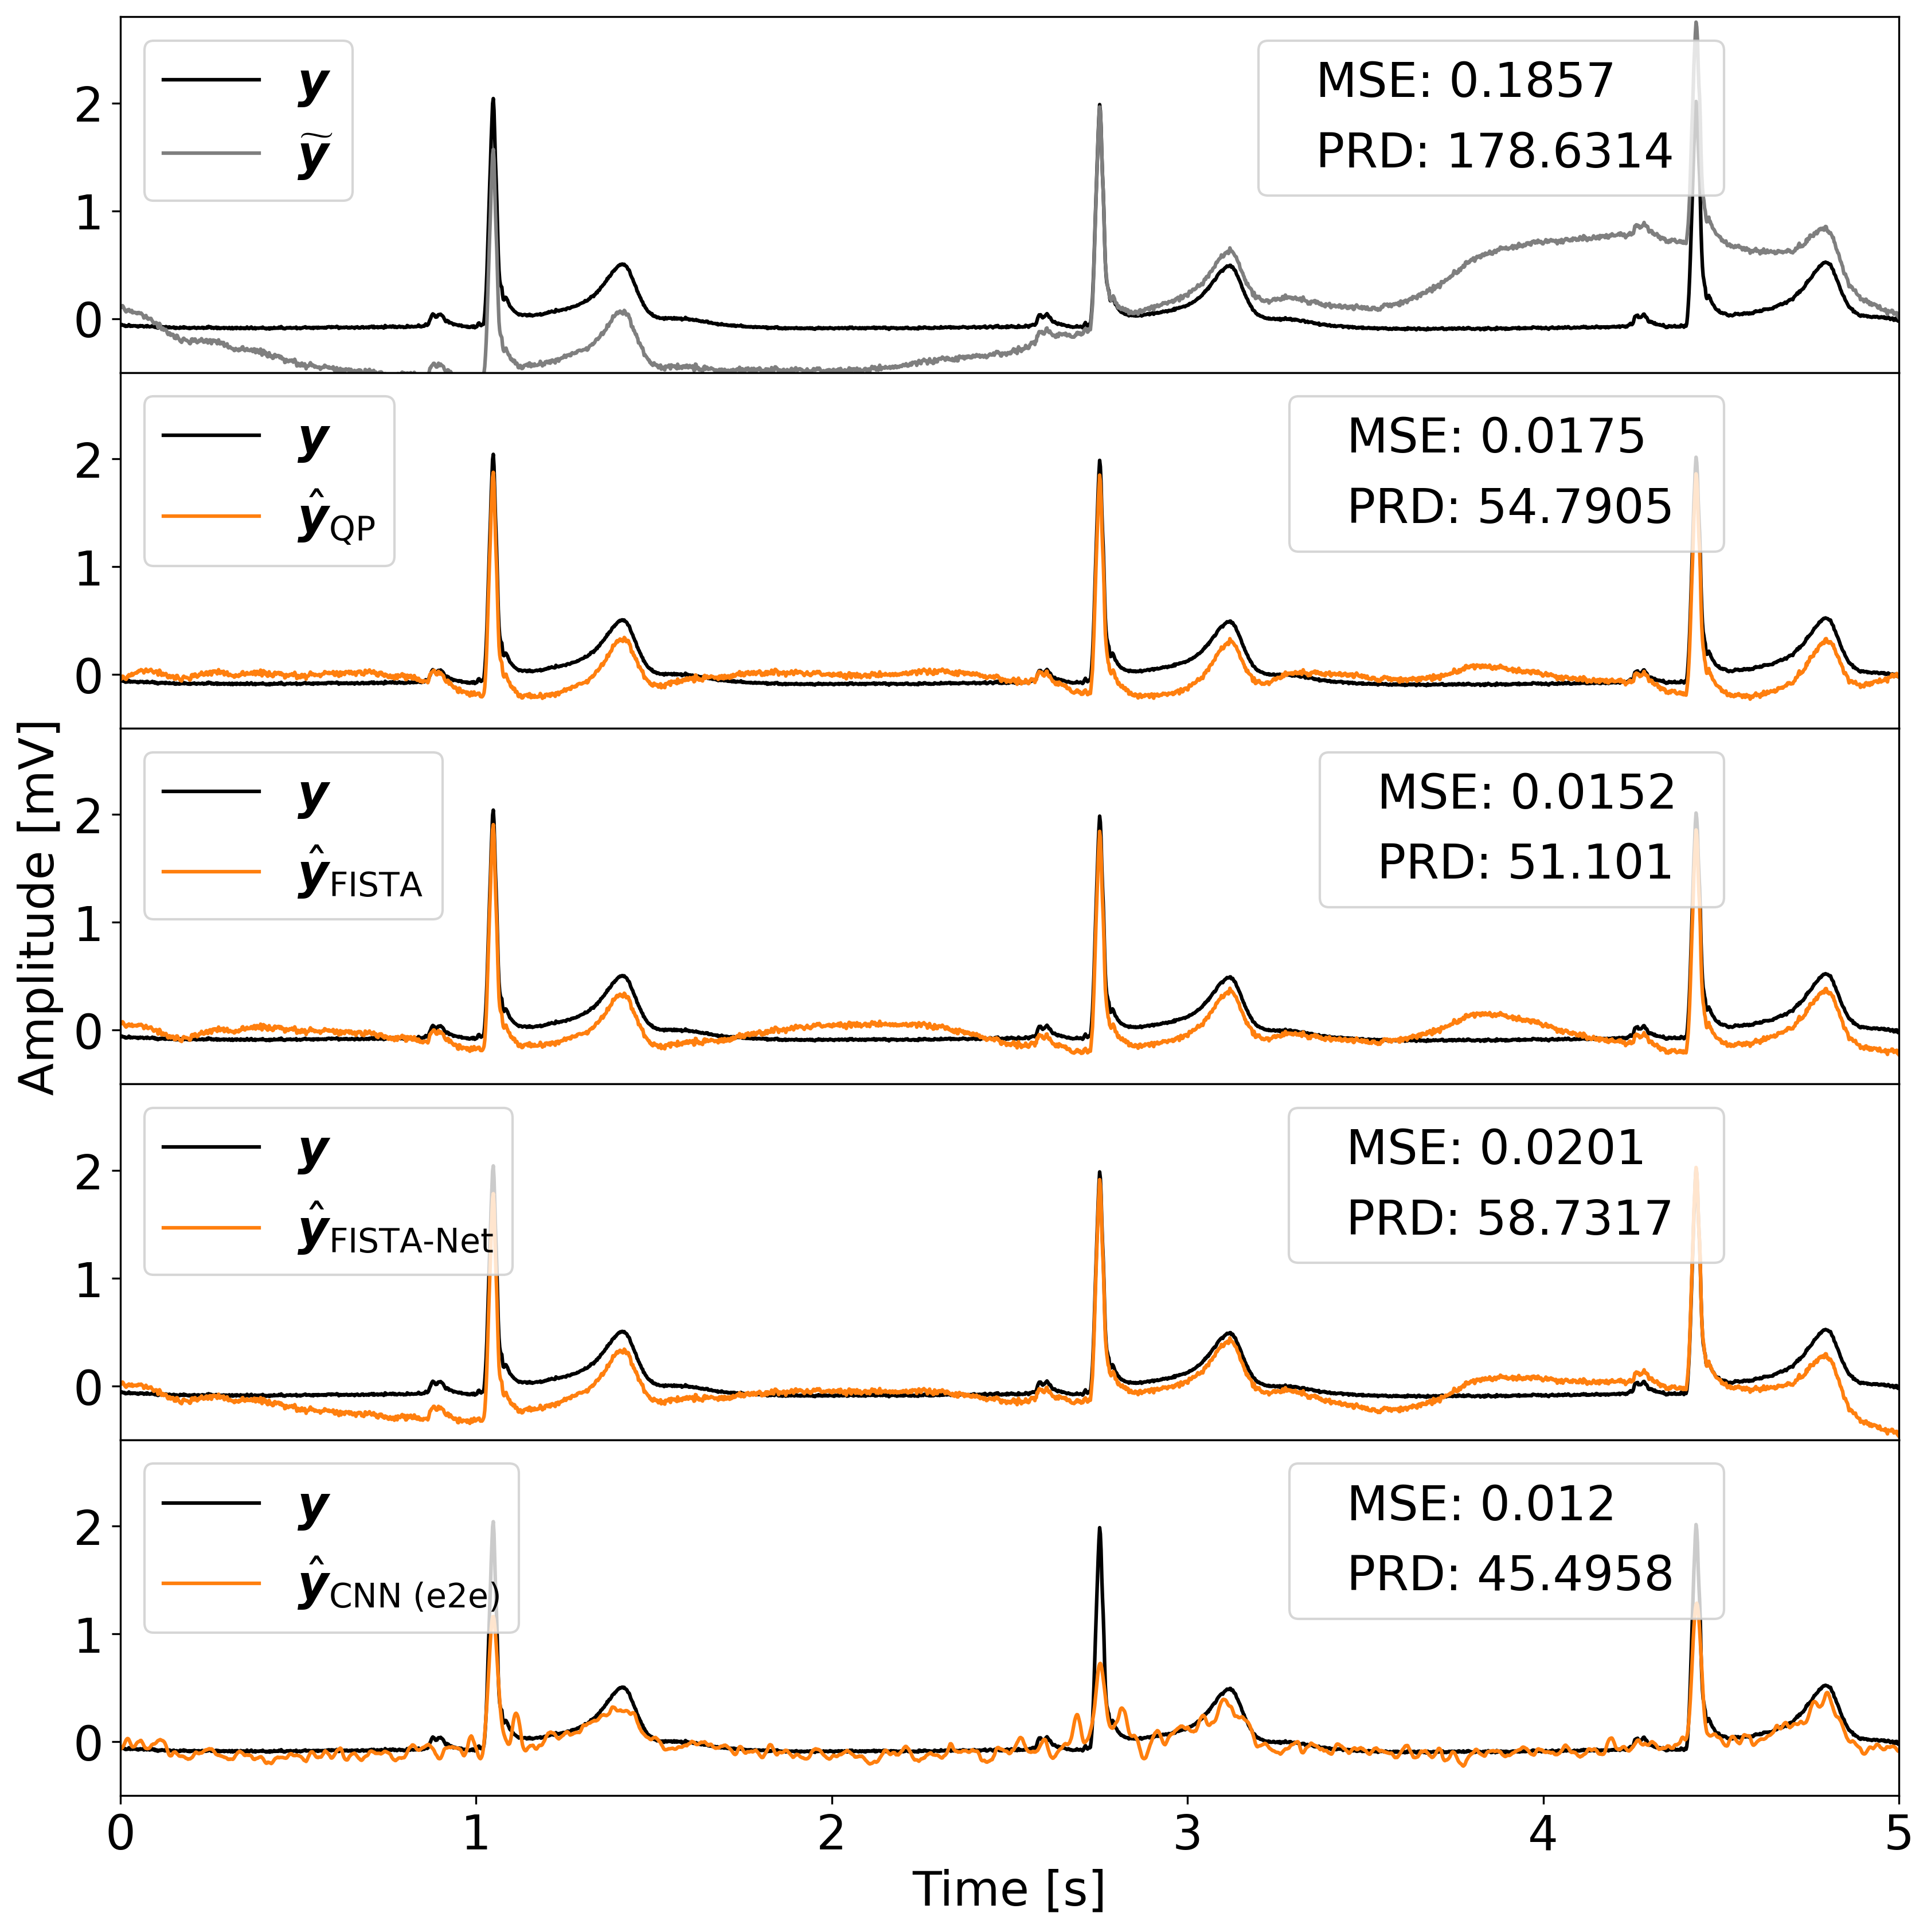

In [119]:
plot_comp_example_subplt(11)

In [11]:
def plot_comp_example(i, filt_list=[True, True, True, True, True, True, True, True, True]):
    global x_in, y_target, denoised_fistanet, denoised_fistanet_cut, denoised_fista, denoised_bpdn, denoised_bpdn1, denoised_bpdn3, denoised_bpdn5
    if filt_list[0]:
        plt.plot(x_in[i, :].cpu(), label='noisy input', linewidth=0.5)
    if filt_list[1]:
        plt.plot(y_target[i, :].cpu(), label='target', linewidth=0.5)
    if filt_list[2]:
        plt.plot(denoised_fistanet[i, :].cpu(), label='FISTA-Net', linewidth=0.5)
    if filt_list[3]:
        plt.plot(denoised_fistanet_cut[i, :].cpu(), label='FISTA-Net cut', linewidth=0.5)
    if filt_list[4]:
        plt.plot(denoised_fista[i, :].cpu(), label='FISTA', linewidth=0.5)
    if filt_list[5]:
        plt.plot(denoised_bpdn[i, :].cpu(), label='BPDN max iter', linewidth=0.5)
    if filt_list[6]:
        plt.plot(denoised_bpdn5[i, :].cpu(), label='BPDN 5 iter', linewidth=0.5)
    if filt_list[7]:
        plt.plot(denoised_bpdn3[i, :].cpu(), label='BPDN 3 iter', linewidth=0.5)
    if filt_list[8]:
        plt.plot(denoised_bpdn1[i, :].cpu(), label='BPDN 1 iter', linewidth=0.5)
    plt.legend()

In [12]:
def plot_comp_example_alpha(i, filt_list=[True, True, True, True, True], ylim=None):
    global x_fistanet, x_fistanet_cut, x_fista, x_bpdn, x_bpdn1, x_bpdn3, x_bpdn5
    if filt_list[0]:
        plt.plot(x_fistanet[i, :].cpu(), label='FISTA-Net')
    if filt_list[0]:
        plt.plot(x_fistanet_cut[i, :].cpu(), label='FISTA-Net cut')
    if filt_list[1]:
        plt.plot(x_fista[i, :].cpu(), label='FISTA', linewidth=0.5)
    if filt_list[1]:
        plt.plot(x_bpdn[i, :].cpu(), label='BPDN max iter', linewidth=0.5)
    if filt_list[2]:
        plt.plot(x_bpdn5[i, :].cpu(), label='BPDN 5 iter', linewidth=0.5)
    if filt_list[3]:
        plt.plot(x_bpdn3[i, :].cpu(), label='BPDN 3 iter', linewidth=0.5)
    if filt_list[4]:
        plt.plot(x_bpdn1[i, :].cpu(), label='BPDN 1 iter', linewidth=0.5)
    if ylim != None:
        plt.ylim(ylim)
    plt.legend()
    plt.savefig(f'plots/x_comp/x_comp_{i}.png')

In [13]:
def plot_comp_example_alpha_subplt(i, font_size=12):
    global x_in, y_target, denoised_fistanet
    global x_fistanet, x_fistanet_cut
    fig, axs = plt.subplots(2, 2, figsize=(12, 3), dpi=300)
    fig.subplots_adjust(0.06, 0.17, .98, 1, .06, 0)

    axs[0, 0].plot(x_fistanet[i].cpu(), color='tab:orange', label=r'$\hat{\boldsymbol{x}}$')
    axs[0, 0].plot(x_fistanet_cut[i].cpu(), linestyle=(0, (5, 5)), color='firebrick', label=r'$\hat{\boldsymbol{x}}$ (trsh)')
    axs[0, 0].set_xticks([])
    axs[0, 0].set_yticks([-50, -30, -10, 10], labels=[-50, -30, -10, 10], fontsize=font_size)
    axs[0, 0].set_xlim([-1, 100])
    axs[0, 0].legend(loc=4, fontsize=font_size)

    axs[1, 0].plot(x_fistanet[i].cpu(), color='tab:orange')
    axs[1, 0].plot(x_fistanet_cut[i].cpu(), linestyle=(0, (5, 5)), color='firebrick')
    axs[1, 0].set_xticks([0, 20, 40, 60, 80, 100], labels=[0, 20, 40, 60, 80, 100], fontsize=font_size)
    axs[1, 0].set_yticks([-0.3, 0, 0.3], labels=[-0.3, 0, 0.3], fontsize=font_size)
    axs[1, 0].set_xlim([-1, 100])
    axs[1, 0].set_ylim([-0.5, 0.5])
    axs[1, 0].set_xlabel(r'Index in $\hat{\boldsymbol{\Psi}}$', fontsize=font_size)

    axs[0, 1].plot(np.linspace(0, 5, 2500), x_in[i, :].cpu(), label=r'$\widetilde{\boldsymbol{y}}$', color='tab:gray')
    axs[0, 1].plot(np.linspace(0, 5, 2500), y_target[i, :].cpu(), label=r'$\boldsymbol{y}$', color='black')
    axs[0, 1].plot(np.linspace(0, 5, 2500), denoised_fistanet[i, :].cpu(), label=r'$\hat{\boldsymbol{y}}$', color='tab:orange')
    axs[0, 1].set_xlim([0, 5])
    axs[0, 1].set_ylim([-0.5, 2.8])
    mse = np.round(((y_target[i, :].cpu() - denoised_fistanet[i, :].cpu())**2).sum()/2500, 4)
    prd = np.round(torch.sqrt(((y_target[i, :].cpu() - denoised_fistanet[i, :].cpu())**2).sum() / (y_target[i, :].cpu()**2).sum())*100, 4)
    legend_val = axs[0, 1].legend(axs[0, 1].get_lines(), [f'MSE: {mse}', f'PRD: {prd}  '], loc='upper right', bbox_to_anchor=(0.935, 1.0),
                               fontsize=font_size, handlelength=0)
    for item in legend_val.legend_handles:
        item.set_visible(False)
    axs[0, 1].add_artist(legend_val)
    axs[0, 1].legend(loc=2, fontsize=font_size)
    axs[0, 1].set_yticks([0.0, 1.0, 2.0], labels=[0, 1, 2], fontsize=font_size)
    axs[0, 1].set_xticks([])

    axs[1, 1].plot(np.linspace(0, 5, 2500), x_in[i, :].cpu(), color='tab:gray')
    axs[1, 1].plot(np.linspace(0, 5, 2500), y_target[i, :].cpu(), color='black')
    axs[1, 1].plot(np.linspace(0, 5, 2500), denoised_fistanet_cut[i, :].cpu(), label=r'$\hat{\boldsymbol{y}}$ (trsh)', color='firebrick')
    axs[1, 1].set_xlim([0, 5])
    axs[1, 1].set_ylim([-0.5, 2.8])
    mse = np.round(((y_target[i, :].cpu() - denoised_fistanet_cut[i, :].cpu())**2).sum()/2500, 4)
    prd = np.round(torch.sqrt(((y_target[i, :].cpu() - denoised_fistanet_cut[i, :].cpu())**2).sum() / (y_target[i, :].cpu()**2).sum())*100, 4)
    legend_val = axs[1, 1].legend(axs[1, 1].get_lines(), [f'MSE: {mse}', f'PRD: {prd}  '], loc='upper right', bbox_to_anchor=(0.935, 1.0),
                               fontsize=font_size, handlelength=0)
    for item in legend_val.legend_handles:
        item.set_visible(False)
    axs[1, 1].add_artist(legend_val)
    axs[1, 1].legend(loc=2, fontsize=font_size)
    axs[1, 1].set_yticks([0.0, 1.0, 2.0], labels=[0, 1, 2], fontsize=font_size)
    axs[1, 1].set_xticks([0, 1, 2, 3, 4, 5], labels=[0, 1, 2, 3, 4, 5], fontsize=font_size)
    axs[1, 1].set_xlabel('Time [s]', fontsize=font_size)

    fig.text(0.01, 0.57, 'Amplitude', va='center', rotation='vertical', fontsize=font_size)

    plt.savefig(f'plots/x_comp_{i}.pdf')
    # plt.savefig(f'plots/x_comp_{i}.png')

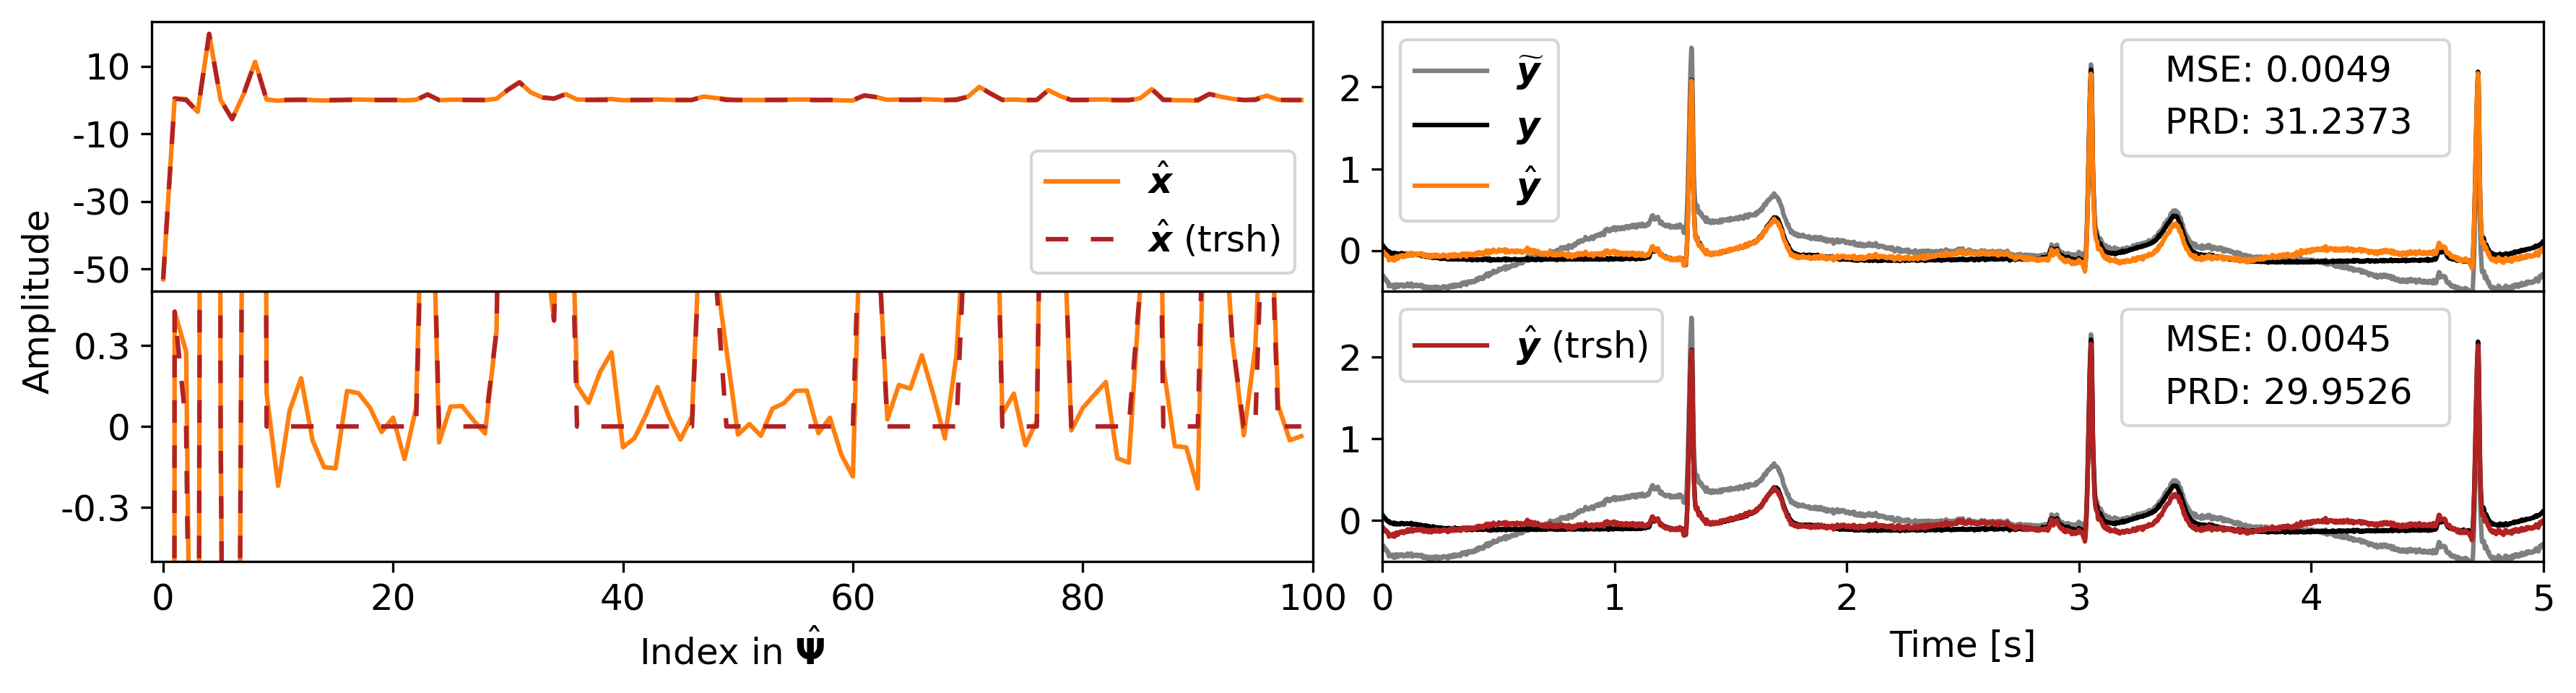

In [139]:
plot_comp_example_alpha_subplt(11)

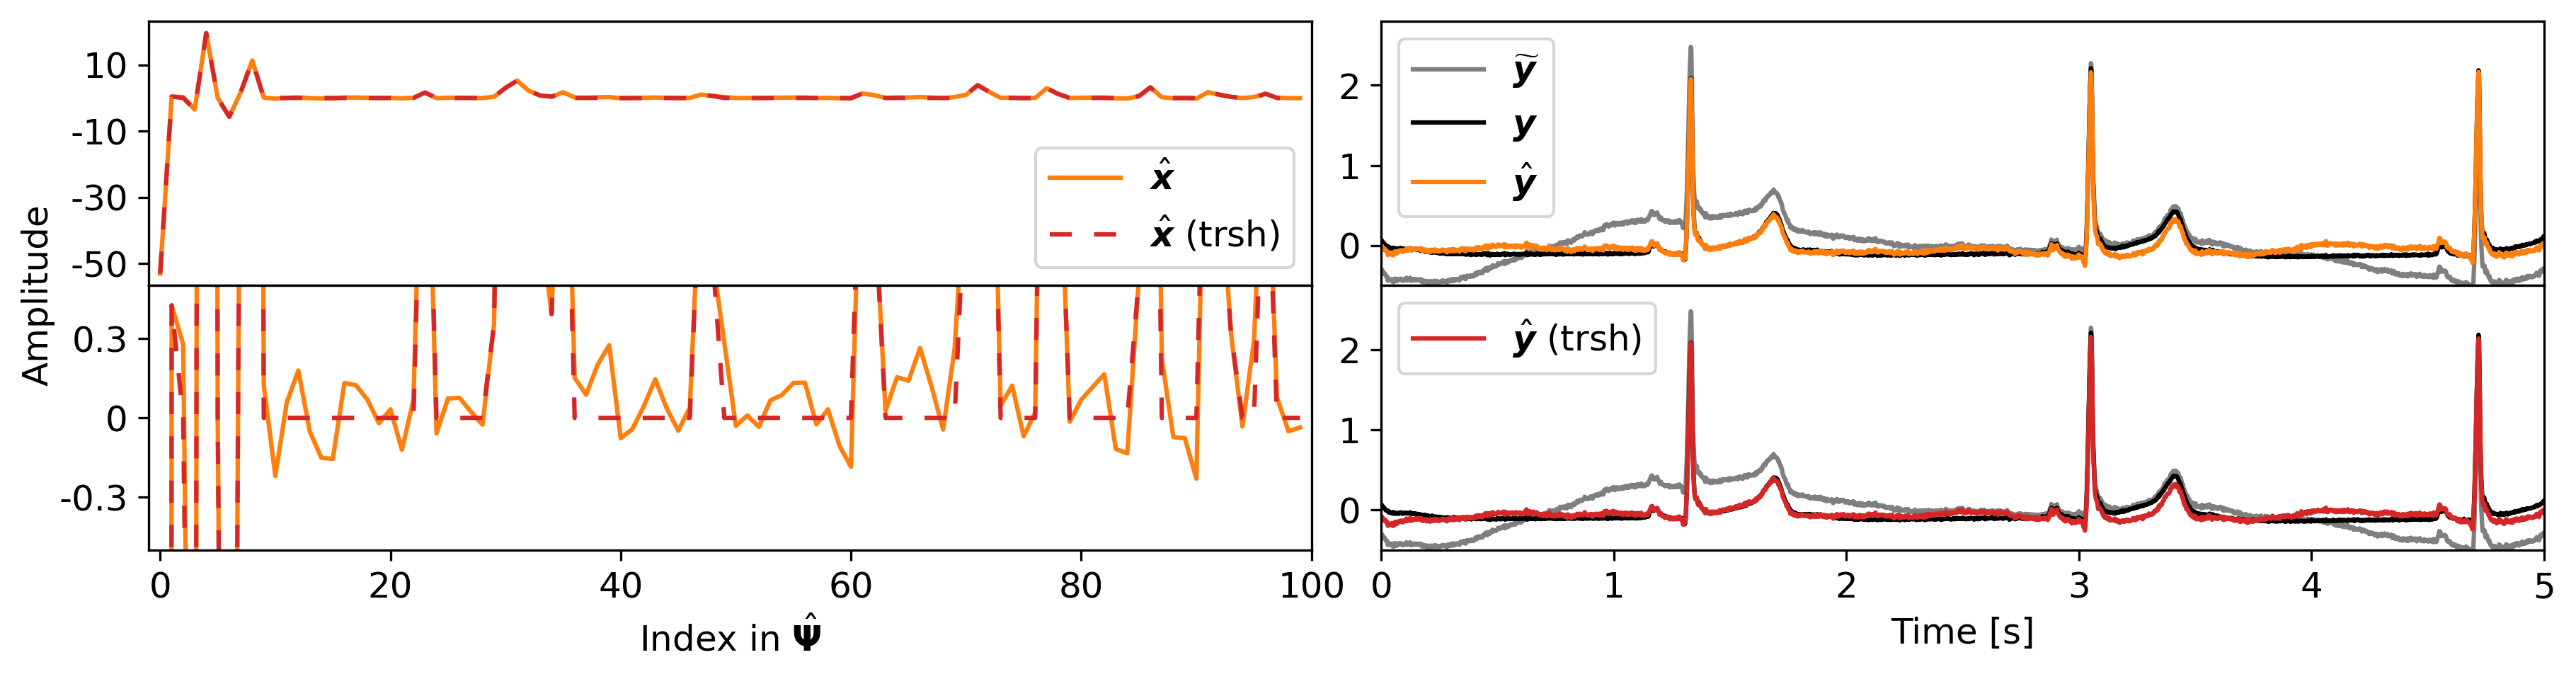

In [23]:
plot_comp_example_alpha_subplt(11)

In [14]:
def gen_l1_latex_string(repr):
    l1s = repr.abs().sum(axis=1)/100
    return f'${round(l1s.mean().item(), 4)} \pm {round(l1s.std().item(), 4)}$'

def gen_l0_latex_string(repr):
    l1s = (repr<1e-10).sum(axis=1).float()/100
    return f'${round(l1s.mean().item(), 4)} \pm {round(l1s.std().item(), 4)}$'

def gen_mse_latex_string(target, denoised):
    mses = ((target - denoised)**2).sum(axis=1)/2500
    return f'${round(mses.mean().item(), 4)} \pm {round(mses.std().item(), 4)}$'

def gen_prd_latex_string(target, denoised):
    prds = torch.sqrt(((target - denoised)**2).sum(axis=1) /\
                      (target**2).sum(axis=1))*100
    return f'${round(prds.mean().item(), 4)} \pm {round(prds.std().item(), 4)}$'

def gen_dsnr_latex_string(inp, target, denoised):
    dsnrs = torch.log10(((inp - target)**2).sum(axis=1) /\
                        ((denoised - target)**2).sum(axis=1))*10
    return f'${round(dsnrs.mean().item(), 4)} \pm {round(dsnrs.std().item(), 4)}$'

def calc_rec_comp_table():
    global x_bpdn, x_fista, x_fistanet, x_cnn
    global x_in, y_target, denoised_bpdn, denoised_fista, denoised_fistanet, denoised_cnn

    for lab, x, den in [('QP\t\t', x_bpdn, denoised_bpdn),
                        ('FISTA\t\t', x_fista, denoised_fista),
                        ('FISTA-Net\t', x_fistanet, denoised_fistanet),
                        ('FISTA-Net cut\t', x_fistanet_cut, denoised_fistanet_cut),
                        ('CNN\t\t', torch.zeros(x_fista.shape), denoised_cnn)]:
        print(lab+' &', end=' ')
        print(gen_mse_latex_string(y_target, den), end=' & ')
        print(gen_prd_latex_string(y_target, den), end=' & ')
        print(gen_dsnr_latex_string(x_in, y_target, den), end=' & ')
        print(gen_l1_latex_string(x), end=' & ')
        print(gen_l0_latex_string(x), end=' \\\\\n')

In [19]:
calc_rec_comp_table()

QP		 & $0.0084 \pm 0.0063$ & $32.7735 \pm 16.6225$ & $4.7631 \pm 5.4707$ & $2.0469 \pm 1.5672$ & $0.4969 \pm 0.0957$ \\
FISTA		 & $0.0058 \pm 0.0063$ & $26.2953 \pm 17.691$ & $7.3992 \pm 5.8198$ & $0.1422 \pm 0.0656$ & $0.929 \pm 0.03$ \\
FISTA-Net	 & $0.0038 \pm 0.0026$ & $21.7779 \pm 10.2856$ & $8.0122 \pm 3.4024$ & $1.2992 \pm 0.0728$ & $0.3476 \pm 0.0578$ \\
FISTA-Net cut	 & $0.0057 \pm 0.0031$ & $26.9292 \pm 10.8989$ & $5.9331 \pm 3.7725$ & $1.2392 \pm 0.0712$ & $0.7495 \pm 0.046$ \\
CNN		 & $0.0272 \pm 0.0104$ & $56.2885 \pm 4.3539$ & $-1.0446 \pm 5.036$ & $0.0 \pm 0.0$ & $1.0 \pm 0.0$ \\


In [82]:
# test for statistical significance in performance difference
from scipy.stats import wilcoxon

def calc_l1(inp, target, repr, denoised):
    return (repr.abs().sum(axis=1)/100).cpu().numpy()

def calc_l0(inp, target, repr, denoised):
    return ((repr<1e-10).sum(axis=1).float()/100).cpu().numpy()

def calc_mse(inp, target, repr, denoised):
    return (((target - denoised)**2).sum(axis=1)/2500).cpu().numpy()

def calc_prd(inp, target, repr, denoised):
    return (torch.sqrt(((target - denoised)**2).sum(axis=1) /\
                       (target**2).sum(axis=1))*100).cpu().numpy()

def calc_dsnr(inp, target, repr, denoised):
    return (torch.log10(((inp - target)**2).sum(axis=1) /\
                         ((denoised - target)**2).sum(axis=1))*10).cpu().numpy()

def perf_wilcoxon(metr_func, alternative='greater'):
    metr_bpdn = metr_func(x_in, y_target, x_bpdn, denoised_bpdn)
    metr_fista = metr_func(x_in, y_target, x_fista, denoised_fista)
    metr_fistanet = metr_func(x_in, y_target, x_fistanet, denoised_fistanet)
    metr_fistanet_cut = metr_func(x_in, y_target, x_fistanet_cut, denoised_fistanet_cut)
    metr_cnn = metr_func(x_in, y_target, torch.zeros(x_bpdn.shape), denoised_cnn)
    
    l1 = [[metr_cnn, 'CNN\t\t'], [metr_bpdn, 'QP\t\t'], [metr_fista, 'FISTA\t\t'], [metr_fistanet_cut, 'FISTA-Net cut\t'], [metr_fistanet, 'FISTA-Net\t']]
    l2 = l1.copy()
    
    for metr1 in l1:
        l2.remove(metr1)
        for metr2 in l2:
            d = np.around(metr1[0] - metr2[0], decimals=4)
            print(metr1[1], metr2[1], wilcoxon(d, alternative=alternative))

In [83]:
perf_wilcoxon(calc_mse)

CNN		 QP		 WilcoxonResult(statistic=473346.0, pvalue=6.112130218832026e-137)
CNN		 FISTA		 WilcoxonResult(statistic=487746.0, pvalue=1.9757240675656076e-151)
CNN		 FISTA-Net cut	 WilcoxonResult(statistic=497620.5, pvalue=4.948716042481669e-164)
CNN		 FISTA-Net	 WilcoxonResult(statistic=500252.0, pvalue=3.4922768891134987e-165)
QP		 FISTA		 WilcoxonResult(statistic=482325.5, pvalue=6.913006885737615e-160)
QP		 FISTA-Net cut	 WilcoxonResult(statistic=370486.5, pvalue=2.135391868710048e-43)
QP		 FISTA-Net	 WilcoxonResult(statistic=453338.5, pvalue=5.341618002846014e-115)
FISTA		 FISTA-Net cut	 WilcoxonResult(statistic=227238.5, pvalue=0.9864904364516965)
FISTA		 FISTA-Net	 WilcoxonResult(statistic=305693.0, pvalue=3.747921736912409e-15)
FISTA-Net cut	 FISTA-Net	 WilcoxonResult(statistic=469404.5, pvalue=2.184146256209385e-143)


In [84]:
perf_wilcoxon(calc_prd)

CNN		 QP		 WilcoxonResult(statistic=475288.0, pvalue=2.7853302859893983e-134)
CNN		 FISTA		 WilcoxonResult(statistic=487105.0, pvalue=1.6644037781784352e-148)
CNN		 FISTA-Net cut	 WilcoxonResult(statistic=498745.0, pvalue=3.1719463282901735e-163)
CNN		 FISTA-Net	 WilcoxonResult(statistic=500054.0, pvalue=6.337589070277897e-165)
QP		 FISTA		 WilcoxonResult(statistic=497108.0, pvalue=4.111688950291122e-161)
QP		 FISTA-Net cut	 WilcoxonResult(statistic=373575.0, pvalue=7.877104273644706e-42)
QP		 FISTA-Net	 WilcoxonResult(statistic=458774.5, pvalue=1.2771582902895723e-115)
FISTA		 FISTA-Net cut	 WilcoxonResult(statistic=223496.0, pvalue=0.9982973059876817)
FISTA		 FISTA-Net	 WilcoxonResult(statistic=318609.5, pvalue=3.6378838539687254e-14)
FISTA-Net cut	 FISTA-Net	 WilcoxonResult(statistic=483827.0, pvalue=1.736049009640912e-144)


In [85]:
perf_wilcoxon(calc_dsnr, 'less')

CNN		 QP		 WilcoxonResult(statistic=23128.5, pvalue=9.766486483030197e-137)
CNN		 FISTA		 WilcoxonResult(statistic=12260.0, pvalue=6.560183556500291e-150)
CNN		 FISTA-Net cut	 WilcoxonResult(statistic=968.0, pvalue=3.024645370103594e-164)
CNN		 FISTA-Net	 WilcoxonResult(statistic=263.0, pvalue=3.6612971324258054e-165)
QP		 FISTA		 WilcoxonResult(statistic=7523.0, pvalue=7.647697326513759e-156)
QP		 FISTA-Net cut	 WilcoxonResult(statistic=155427.5, pvalue=1.5369013154665408e-25)
QP		 FISTA-Net	 WilcoxonResult(statistic=50249.0, pvalue=1.528122007013648e-106)
FISTA		 FISTA-Net cut	 WilcoxonResult(statistic=348035.5, pvalue=1.0)
FISTA		 FISTA-Net	 WilcoxonResult(statistic=211595.5, pvalue=1.162161492361642e-05)
FISTA-Net cut	 FISTA-Net	 WilcoxonResult(statistic=15865.0, pvalue=1.7958426515588997e-145)


In [86]:
perf_wilcoxon(calc_l0)

CNN		 QP		 WilcoxonResult(statistic=500500.0, pvalue=1.509984718343321e-165)
CNN		 FISTA		 WilcoxonResult(statistic=499500.0, pvalue=7.930625768589918e-166)
CNN		 FISTA-Net cut	 WilcoxonResult(statistic=500500.0, pvalue=7.261352251249208e-166)
CNN		 FISTA-Net	 WilcoxonResult(statistic=500500.0, pvalue=1.287773788506996e-165)
QP		 FISTA		 WilcoxonResult(statistic=0.0, pvalue=1.0)
QP		 FISTA-Net cut	 WilcoxonResult(statistic=144.0, pvalue=1.0)
QP		 FISTA-Net	 WilcoxonResult(statistic=471230.0, pvalue=5.0259240629192375e-151)
FISTA		 FISTA-Net cut	 WilcoxonResult(statistic=500500.0, pvalue=8.626400617329752e-166)
FISTA		 FISTA-Net	 WilcoxonResult(statistic=500500.0, pvalue=1.1996146701649022e-165)
FISTA-Net cut	 FISTA-Net	 WilcoxonResult(statistic=500500.0, pvalue=1.262342939851803e-165)


In [87]:
perf_wilcoxon(calc_l1)

CNN		 QP		 WilcoxonResult(statistic=0.0, pvalue=1.0)
CNN		 FISTA		 WilcoxonResult(statistic=0.0, pvalue=1.0)
CNN		 FISTA-Net cut	 WilcoxonResult(statistic=0.0, pvalue=1.0)
CNN		 FISTA-Net	 WilcoxonResult(statistic=0.0, pvalue=1.0)
QP		 FISTA		 WilcoxonResult(statistic=500500.0, pvalue=1.6629145882507326e-165)
QP		 FISTA-Net cut	 WilcoxonResult(statistic=369278.0, pvalue=4.1797748669129624e-39)
QP		 FISTA-Net	 WilcoxonResult(statistic=362646.5, pvalue=4.3531635435852025e-35)
FISTA		 FISTA-Net cut	 WilcoxonResult(statistic=0.0, pvalue=1.0)
FISTA		 FISTA-Net	 WilcoxonResult(statistic=0.0, pvalue=1.0)
FISTA-Net cut	 FISTA-Net	 WilcoxonResult(statistic=0.0, pvalue=1.0)


## Compare average MSE on testing dataset (10000 samples)

In [8]:
x_fista = torch.Tensor(np.load('data/generated/BW_alphas-FISTA_10000_2025-04-12-18-12-01.npy')).double()

In [19]:
trn_ldr, val_ldr, tst_ldr = DataSplit(DATA_DIR, NOISE_TYPE, DATA_FILE_GEN, DATA_FILE_SIGS, DATA_FILE_NOISE, DATA_FILE_BPDN_1,
                                      DATA_FILE_BPDN_FINAL, TVT_SPLIT, BATCH_SIZE)

l_x_bpdn1 = []
l_x_in = []
l_x_bpdn = []
l_y_target = []
l_denoised_bpdn1 = []
l_denoised_bpdn = []
l_denoised_fista = []
l_denoised_fistanet = []
l_denoised_fistanet_cut = []

for batch_idy, (b_x_in, b_y_target, b_x_bpdn1, b_x_bpdn) in enumerate(tst_ldr):
    fst = batch_idy * BATCH_SIZE
    lst = fst + b_x_in.shape[0]
    b_x_fista = x_fista[fst:lst]
    b_x_fistanet = x_fistanet[fst:lst]
    b_x_fistanet_cut = x_fistanet_cut[fst:lst]
    
    b_x_bpdn1 = b_x_bpdn1.clone().detach().to(device=device)
    b_x_in = b_x_in.clone().detach().to(device=device)
    b_x_bpdn = b_x_bpdn.clone().detach().to(device=device)
    b_y_target = b_y_target.clone().detach().to(device=device)
    b_x_fista = torch.Tensor(b_x_fista).to(device).double()
    
    b_denoised_bpdn1 = b_x_in - torch.bmm(dictionary, b_x_bpdn1.unsqueeze(2)).squeeze()
    b_denoised_bpdn = b_x_in - torch.bmm(dictionary, b_x_bpdn.unsqueeze(2)).squeeze()
    b_denoised_fista = b_x_in - torch.bmm(dictionary, b_x_fista.unsqueeze(2)).squeeze()
    b_denoised_fistanet = b_x_in - torch.bmm(dictionary, b_x_fistanet.unsqueeze(2)).squeeze()
    b_denoised_fistanet_cut = b_x_in - torch.bmm(dictionary, b_x_fistanet_cut.unsqueeze(2)).squeeze()

    noise = torch.bmm(dictionary, b_x_fistanet.unsqueeze(2)).squeeze()

    l_x_bpdn1.append(b_x_bpdn1)
    l_x_in.append(b_x_in)
    l_x_bpdn.append(b_x_bpdn)
    l_y_target.append(b_y_target)
    l_denoised_bpdn1.append(b_denoised_bpdn1)
    l_denoised_bpdn.append(b_denoised_bpdn)
    l_denoised_fista.append(b_denoised_fista)
    l_denoised_fistanet.append(b_denoised_fistanet)
    l_denoised_fistanet_cut.append(b_denoised_fistanet_cut)

x_bpdn1 = torch.stack(l_x_bpdn1, dim=0).flatten(0, 1)
x_in = torch.stack(l_x_in, dim=0).flatten(0, 1)
x_bpdn = torch.stack(l_x_bpdn, dim=0).flatten(0, 1)
y_target = torch.stack(l_y_target, dim=0).flatten(0, 1)
denoised_bpdn1 = torch.stack(l_denoised_bpdn1, dim=0).flatten(0, 1)
denoised_bpdn = torch.stack(l_denoised_bpdn, dim=0).flatten(0, 1)
denoised_fista = torch.stack(l_denoised_fista, dim=0).flatten(0, 1)
denoised_fistanet = torch.stack(l_denoised_fistanet, dim=0).flatten(0, 1)
denoised_fistanet_cut = torch.stack(l_denoised_fistanet_cut, dim=0).flatten(0, 1)

In [11]:
# Remove the worst to improve std in table - does not help that much
perc = 558
mses = ((y_target - denoised_fistanet)**2).sum(axis=1)/2500
id_worst_fistanet = np.argpartition(mses.clone().cpu().numpy(), -perc)[-perc:]
mses = ((y_target - denoised_bpdn)**2).sum(axis=1)/2500
id_worst_bpdn = np.argpartition(mses.clone().cpu().numpy(), -perc)[-perc:]

In [12]:
to_remove = set(id_worst_fistanet).union(set(id_worst_bpdn))
to_keep = list(set(list(range(y_target.shape[0]))) - to_remove)
print(len(to_remove))

740


In [13]:
x_bpdn1 = x_bpdn1[to_keep]
x_in = x_in[to_keep]
x_bpdn = x_bpdn[to_keep]
y_target = y_target[to_keep]
denoised_bpdn1 = denoised_bpdn1[to_keep]
denoised_bpdn = denoised_bpdn[to_keep]
denoised_fista = denoised_fista[to_keep]
denoised_fistanet = denoised_fistanet[to_keep]
denoised_fistanet_cut = denoised_fistanet_cut[to_keep]
denoised_cnn = denoised_cnn[to_keep]

## Compare average MSE on testing dataset (1000 samples)

In [14]:
trn_ldr, val_ldr, tst_ldr = DataSplit(DATA_DIR, NOISE_TYPE, DATA_FILE_GEN, DATA_FILE_SIGS, DATA_FILE_NOISE, DATA_FILE_BPDN_1,
                                      DATA_FILE_BPDN_FINAL, TVT_SPLIT, BATCH_SIZE)
x_in, y_target, x_bpdn1, x_bpdn = next(iter(tst_ldr))
trn_ldr, val_ldr, tst_ldr = DataSplit(DATA_DIR, NOISE_TYPE, DATA_FILE_GEN, DATA_FILE_SIGS, DATA_FILE_NOISE, DATA_FILE_BPDN_3,
                                      DATA_FILE_BPDN_FINAL, TVT_SPLIT, BATCH_SIZE)
x_in, y_target, x_bpdn3, x_bpdn = next(iter(tst_ldr))
trn_ldr, val_ldr, tst_ldr = DataSplit(DATA_DIR, NOISE_TYPE, DATA_FILE_GEN, DATA_FILE_SIGS, DATA_FILE_NOISE, DATA_FILE_BPDN_5,
                                      DATA_FILE_BPDN_FINAL, TVT_SPLIT, BATCH_SIZE)
x_in, y_target, x_bpdn5, x_bpdn = next(iter(tst_ldr))

x_bpdn = torch.Tensor(np.load('data/generated/BW_alphas-qp_test_10000_2024-04-07-12-43-32.npy')).double()

In [15]:
x_fista = np.zeros((x_in.shape[0], dict_np.shape[1]))
for i in tqdm(range(x_in.shape[0])):
    x_fista[i, :], _, _ = pylops.optimization.sparsity.fista(
                                        pylops.MatrixMult(dict_np), x_in[i].clone().cpu().numpy(),
                                        niter=100, eps=5e-1, tol=1e-3)

100%|██████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:48<00:00, 20.45it/s]


In [16]:
# np.save(f'data/generated/BW_alphas-FISTA_10000_2025-04-12-18-12-01.npy', x_fista.clone().cpu().numpy())

In [17]:
x_bpdn1 = x_bpdn1.clone().detach().to(device=device)
x_bpdn3 = x_bpdn3.clone().detach().to(device=device)
x_bpdn5 = x_bpdn5.clone().detach().to(device=device)
x_in = x_in.clone().detach().to(device=device)
x_bpdn = x_bpdn.clone().detach().to(device=device)
y_target = y_target.clone().detach().to(device=device)
x_fista = torch.Tensor(x_fista).to(device).double()

denoised_bpdn1 = x_in - torch.bmm(dictionary, x_bpdn1.unsqueeze(2)).squeeze()
denoised_bpdn3 = x_in - torch.bmm(dictionary, x_bpdn3.unsqueeze(2)).squeeze()
denoised_bpdn5 = x_in - torch.bmm(dictionary, x_bpdn5.unsqueeze(2)).squeeze()
denoised_bpdn = x_in - torch.bmm(dictionary, x_bpdn.unsqueeze(2)).squeeze()
denoised_fista = x_in - torch.bmm(dictionary, x_fista.unsqueeze(2)).squeeze()
denoised_fistanet = x_in - torch.bmm(dictionary, x_fistanet.unsqueeze(2)).squeeze()
denoised_fistanet_cut = x_in - torch.bmm(dictionary, x_fistanet_cut.unsqueeze(2)).squeeze()

In [18]:
loss = torch.nn.MSELoss()
losses_MSE = {
    'fistanet': loss(y_target, denoised_fistanet).item(),
    'fistanet_cut': loss(y_target, denoised_fistanet_cut).item(),
    'fista': loss(y_target, denoised_fista).item(),
    'bpdn_maxiter': loss(y_target, denoised_bpdn).item(),
    'bpdn_5iter': loss(y_target, denoised_bpdn5).item(),
    'bpdn_3iter': loss(y_target, denoised_bpdn3).item(),
    'bpdn_1iter': loss(y_target, denoised_bpdn1).item(),
}

In [13]:
plot_bar_comp(losses_MSE, 'MSE', 'Average MSE loss values on testing data (1000 samples)')

NameError: name 'plot_bar_comp' is not defined

## Compare single BW denoising examples

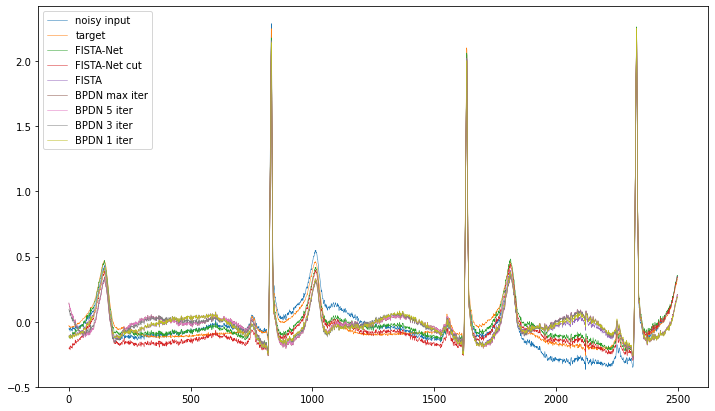

In [18]:
plot_comp_example(20)

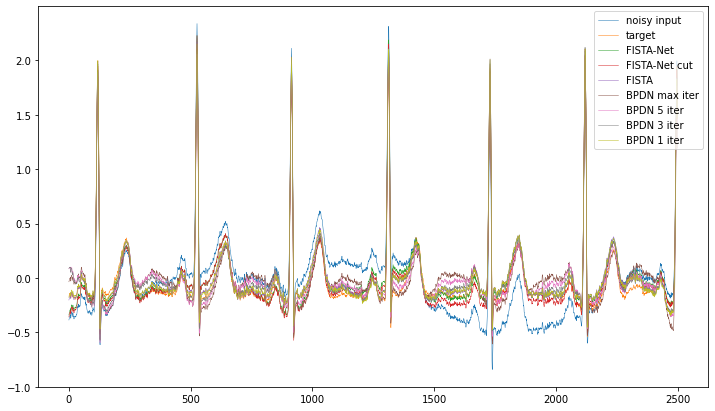

In [70]:
plot_comp_example(210)

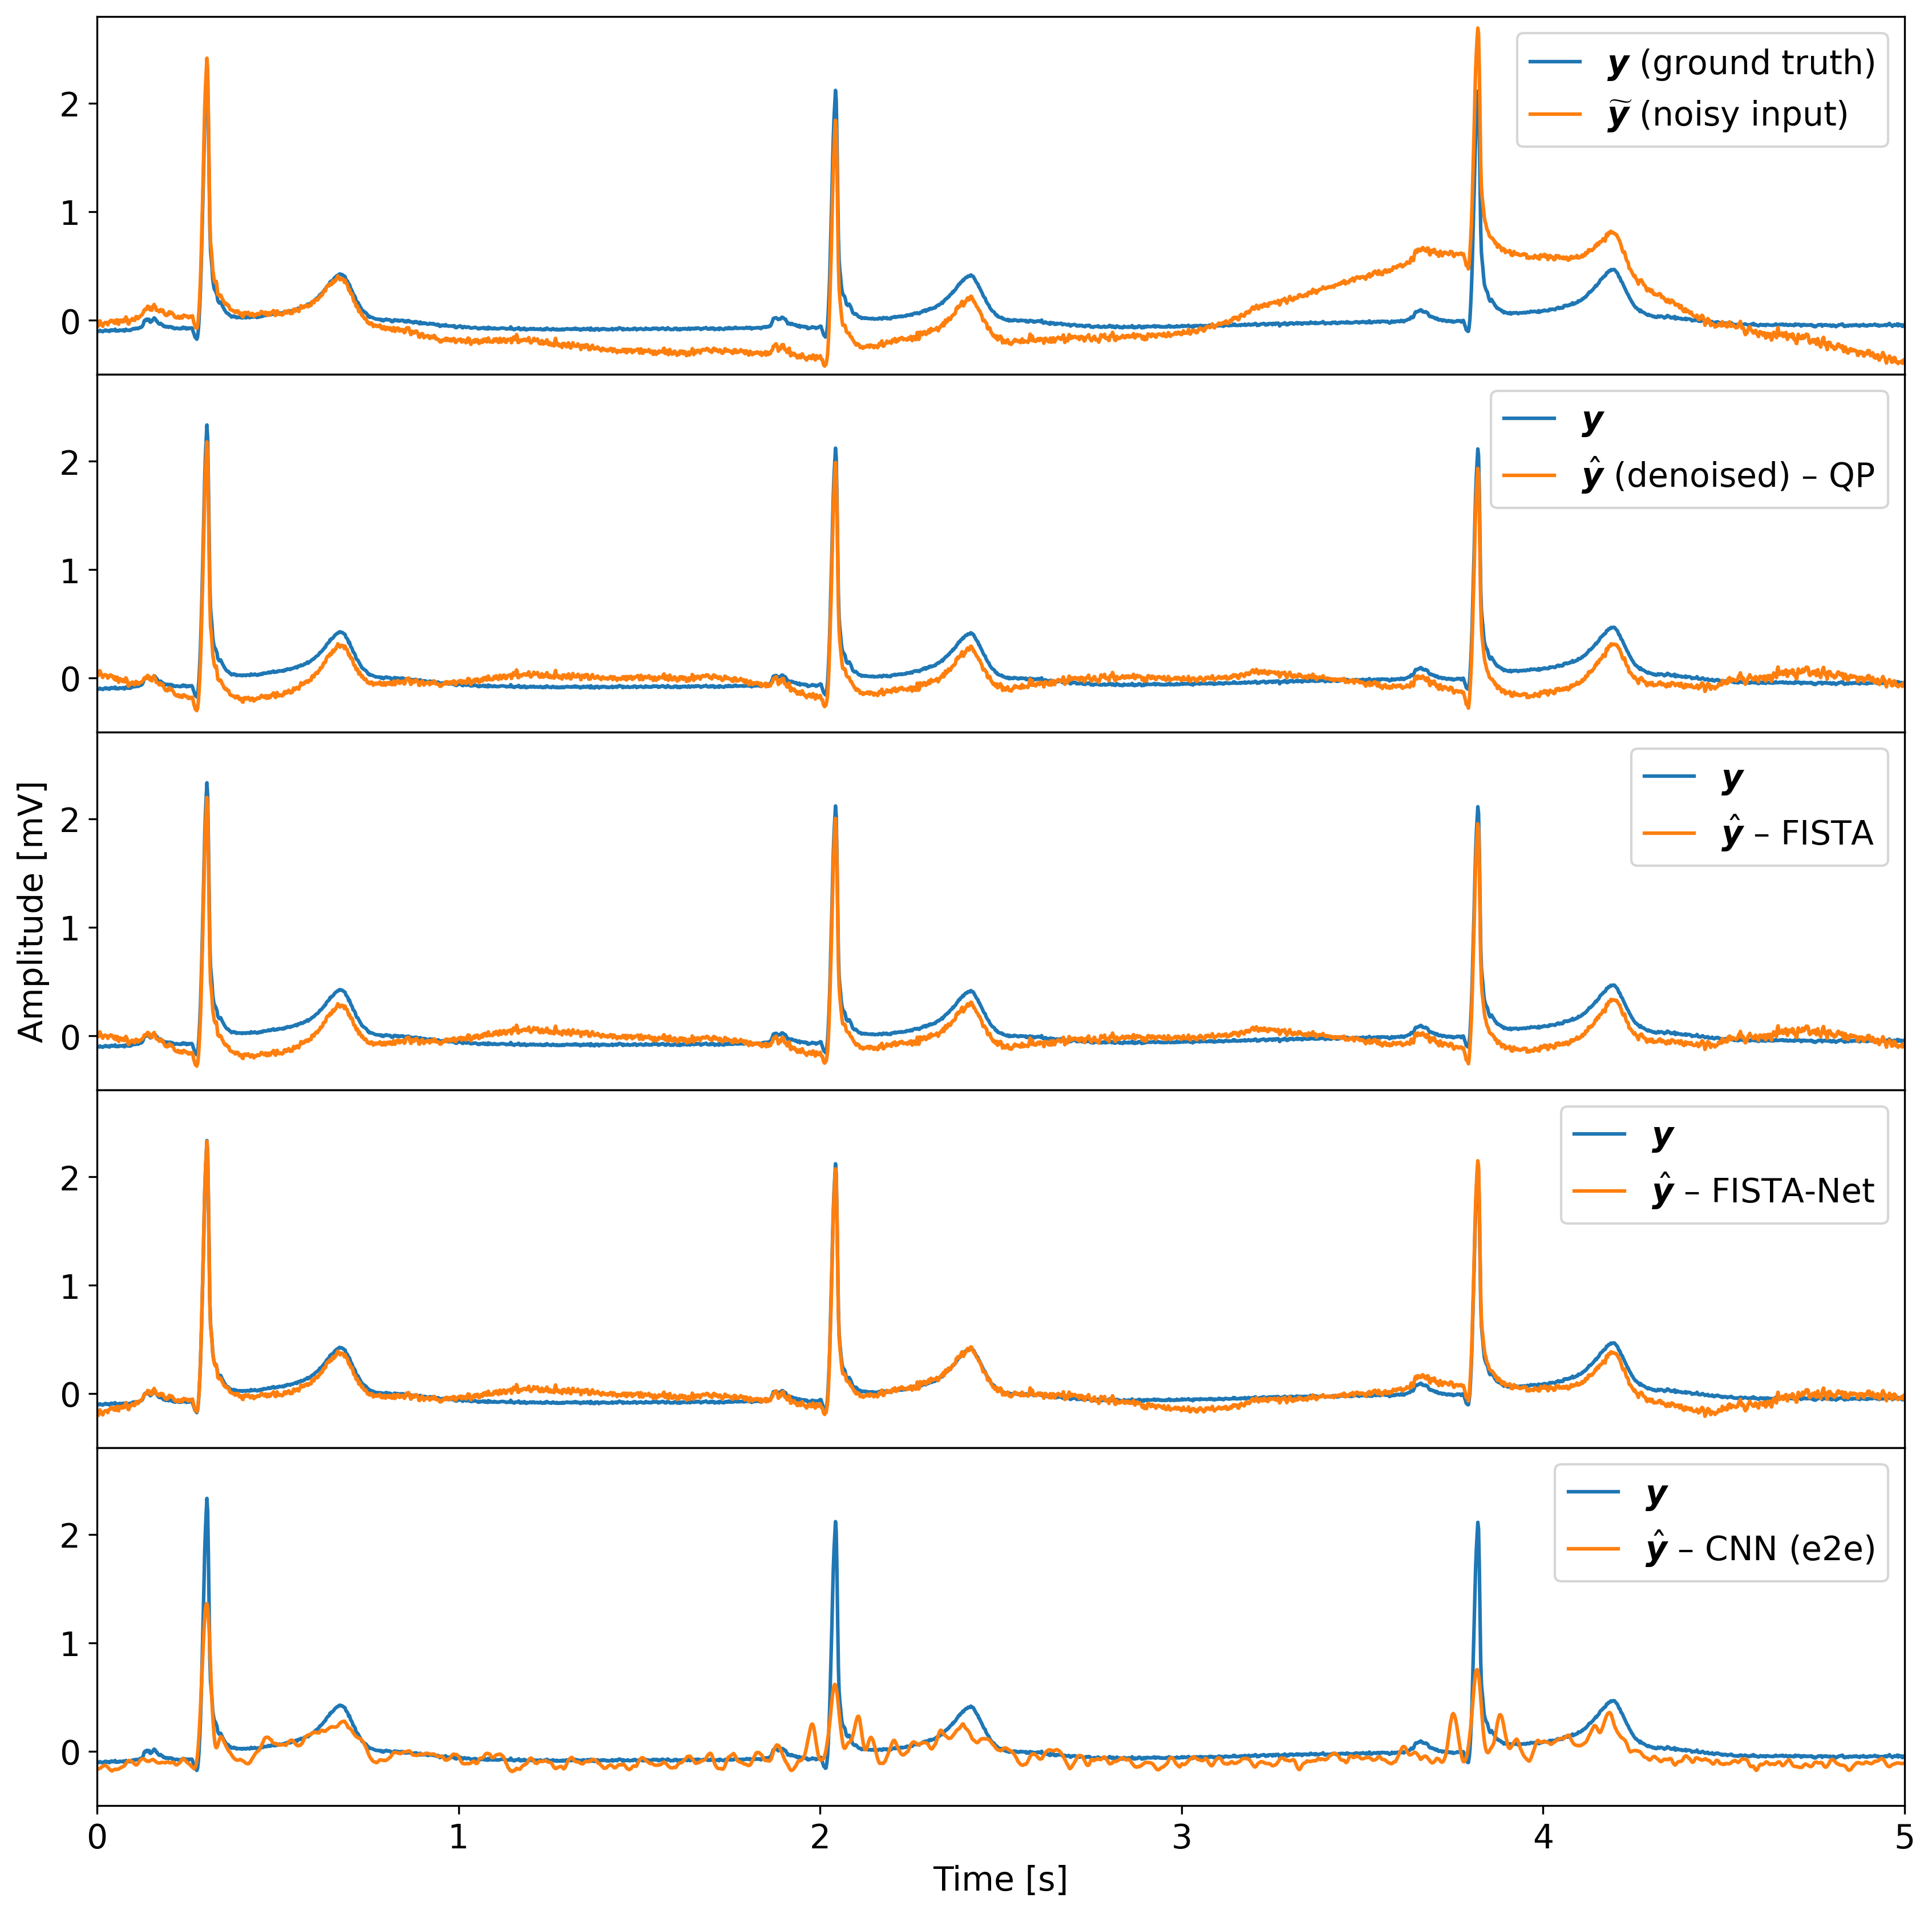

In [305]:
plot_comp_example_subplt(5)

## Compare sparcity - percentage of non-zero elements

In [63]:
non_zero_perc_func = lambda x: torch.sum(x.abs().cpu().squeeze().detach()>1e-6).item() / (x.shape[0] * x.shape[1]) * 100
non_zero_perc = {
    'fistanet': non_zero_perc_func(x_fistanet),
    'fistanet_cut': non_zero_perc_func(x_fistanet_cut),
    'fista': non_zero_perc_func(x_fista),
    'bpdn_maxiter': non_zero_perc_func(x_bpdn),
    'bpdn_5iter': non_zero_perc_func(x_bpdn1),
    'bpdn_3iter': non_zero_perc_func(x_bpdn3),
    'bpdn_1iter': non_zero_perc_func(x_bpdn5),
}

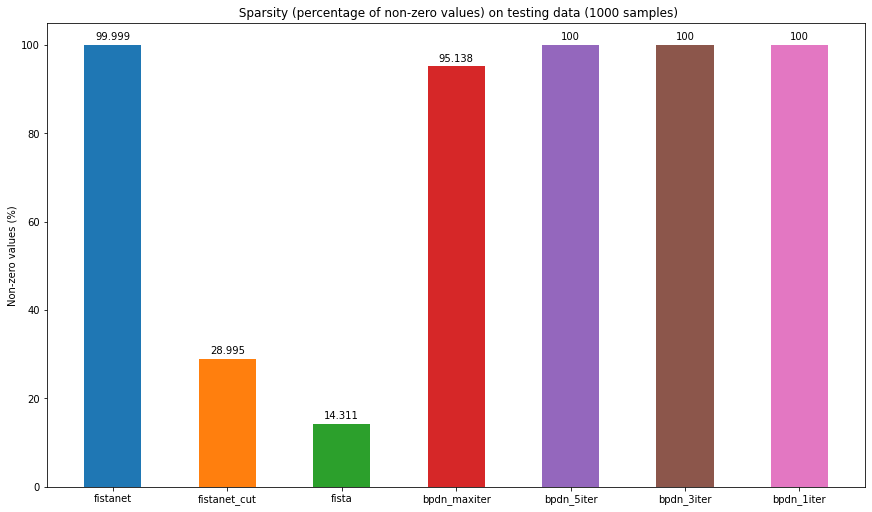

In [64]:
plot_bar_comp(non_zero_perc, 'Non-zero values (%)', ' Sparsity (percentage of non-zero values) on testing data (1000 samples)')

In [65]:
non_zero_perc_func = lambda x: torch.sum(x.abs().cpu().squeeze().detach()>1e-3).item() / (x.shape[0] * x.shape[1]) * 100
non_zero_perc = {
    'fistanet': non_zero_perc_func(x_fistanet),
    'fistanet_cut': non_zero_perc_func(x_fistanet_cut),
    'bpdn_maxiter': non_zero_perc_func(x_bpdn),
    'bpdn_5iter': non_zero_perc_func(x_bpdn1),
    'bpdn_3iter': non_zero_perc_func(x_bpdn3),
    'bpdn_1iter': non_zero_perc_func(x_bpdn5),
}

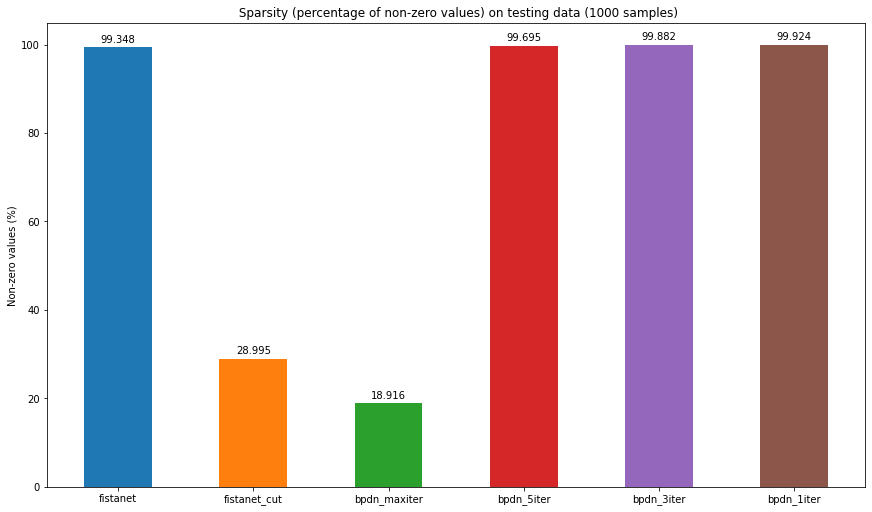

In [66]:
plot_bar_comp(non_zero_perc, 'Non-zero values (%)', ' Sparsity (percentage of non-zero values) on testing data (1000 samples)')

In [130]:
non_zero_perc_func = lambda x: torch.sum(x.abs().cpu().squeeze().detach()>1e-5).item() / (x.shape[0] * x.shape[1])
non_zero_perc = {
    'QP': non_zero_perc_func(x_bpdn),
    'FISTA': non_zero_perc_func(x_fista),
    'fistanet': non_zero_perc_func(x_fistanet),
    'fistanet_cut': non_zero_perc_func(x_fistanet_cut),
}

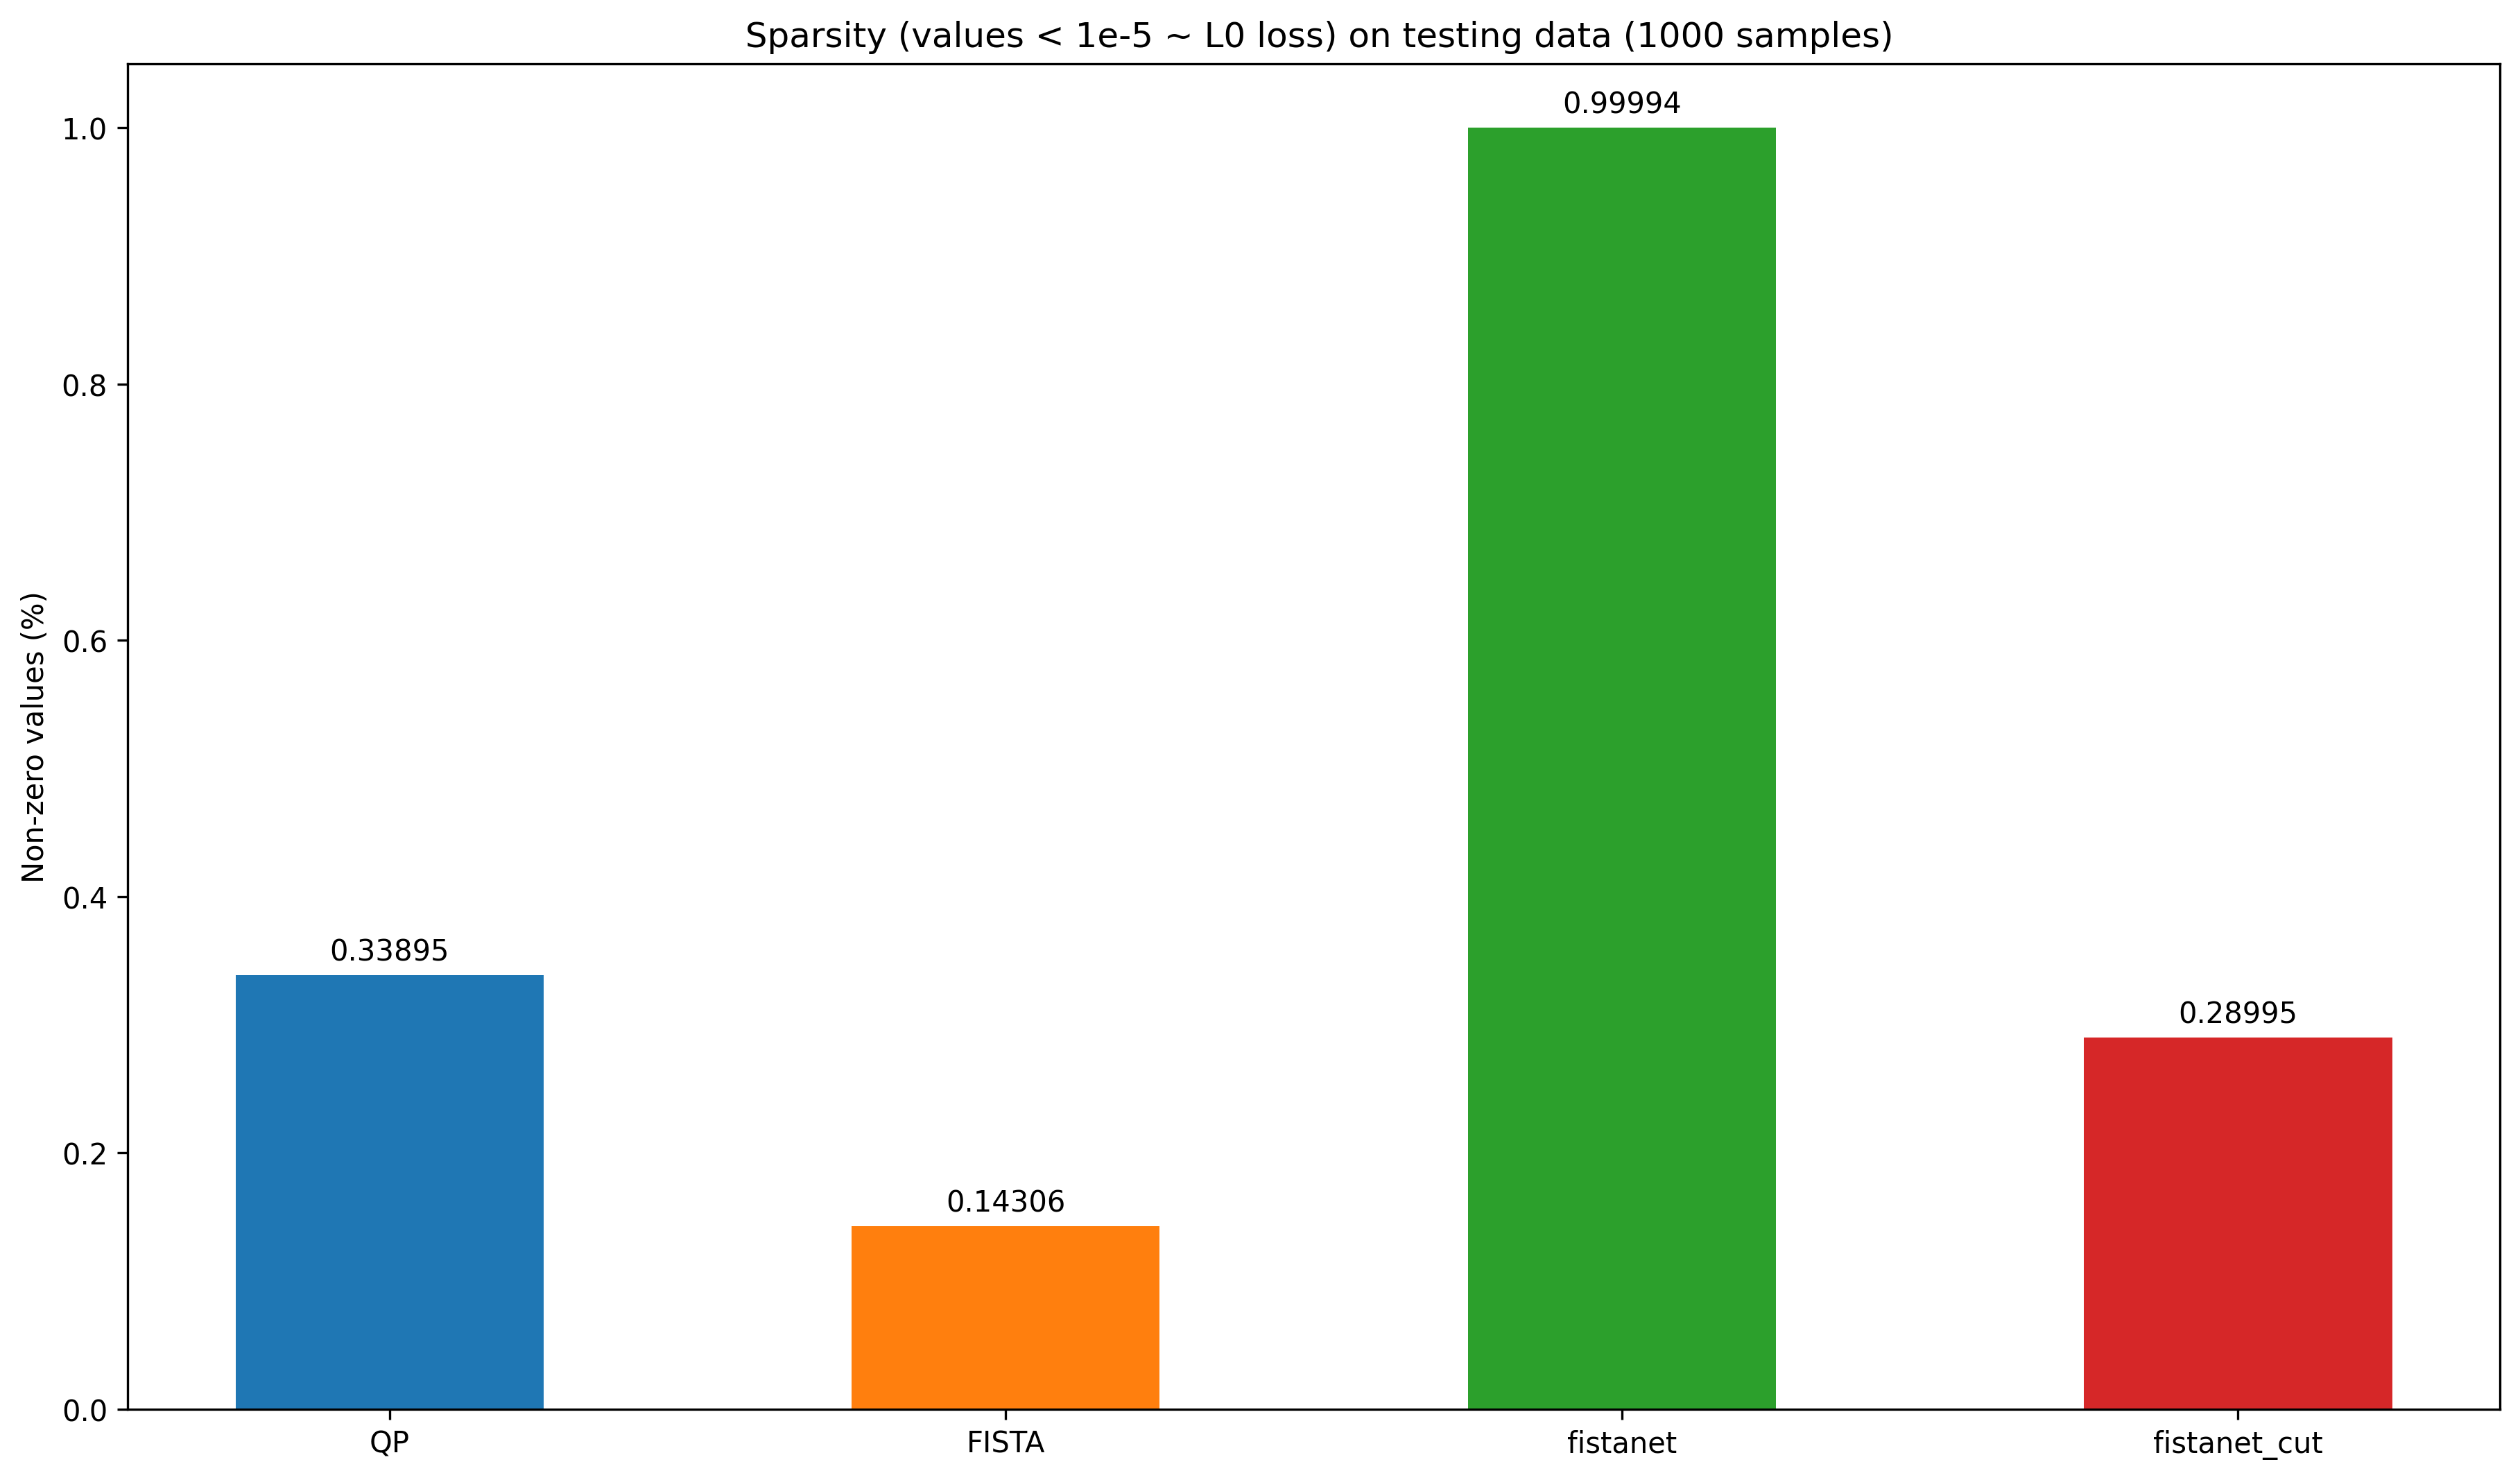

In [131]:
plot_bar_comp(non_zero_perc, 'Non-zero values (%)', ' Sparsity (values < 1e-5 ~ L0 loss) on testing data (1000 samples)')

In [127]:
def min_max_norm(x):
    mins = x.min(dim=1).values.repeat((x.shape[1], 1)).T
    maxs = x.max(dim=1).values.repeat((x.shape[1], 1)).T
    return (x - mins) / (maxs - mins)
def max_abs_norm(x):
    mins = x.min(dim=1).values.repeat((x.shape[1], 1)).T
    maxs = x.max(dim=1).values.repeat((x.shape[1], 1)).T
    absmax = torch.stack([mins, maxs]).abs().max(dim=0).values
    return x / absmax
non_zero_perc_func = lambda x: torch.sum(x.abs().cpu().squeeze().detach()>1e-5).item() / (x.shape[0] * x.shape[1]) * 100
non_zero_perc_norm = {
    'fistanet': non_zero_perc_func(max_abs_norm(x_fistanet)),
    'fistanet_cut': non_zero_perc_func(max_abs_norm(x_fistanet_cut)),
    'bpdn_maxiter': non_zero_perc_func(max_abs_norm(x_bpdn)),
    'bpdn_5iter': non_zero_perc_func(max_abs_norm(x_bpdn5)),
    'bpdn_3iter': non_zero_perc_func(max_abs_norm(x_bpdn3)),
    'bpdn_1iter': non_zero_perc_func(max_abs_norm(x_bpdn1))
}

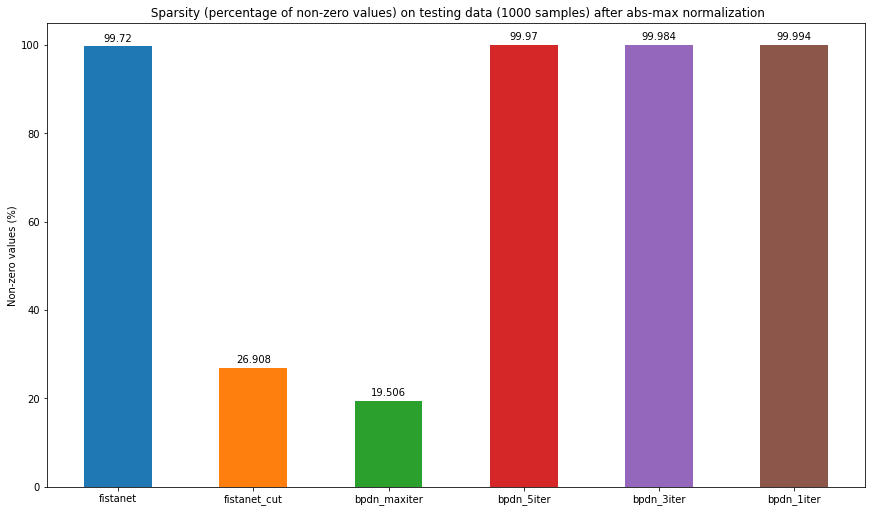

In [128]:
plot_bar_comp(non_zero_perc_norm, 'Non-zero values (%)', ' Sparsity (percentage of non-zero values) on testing data (1000 samples) after abs-max normalization')

In [112]:
loss = lambda x: torch.mean(torch.abs(x)).cpu()
losses_L1 = {
    'qp': loss(x_bpdn),
    'fista':  loss(x_fista),
    'fistanet': loss(x_fistanet),
    'fistanet_cut': loss(x_fistanet_cut),
}

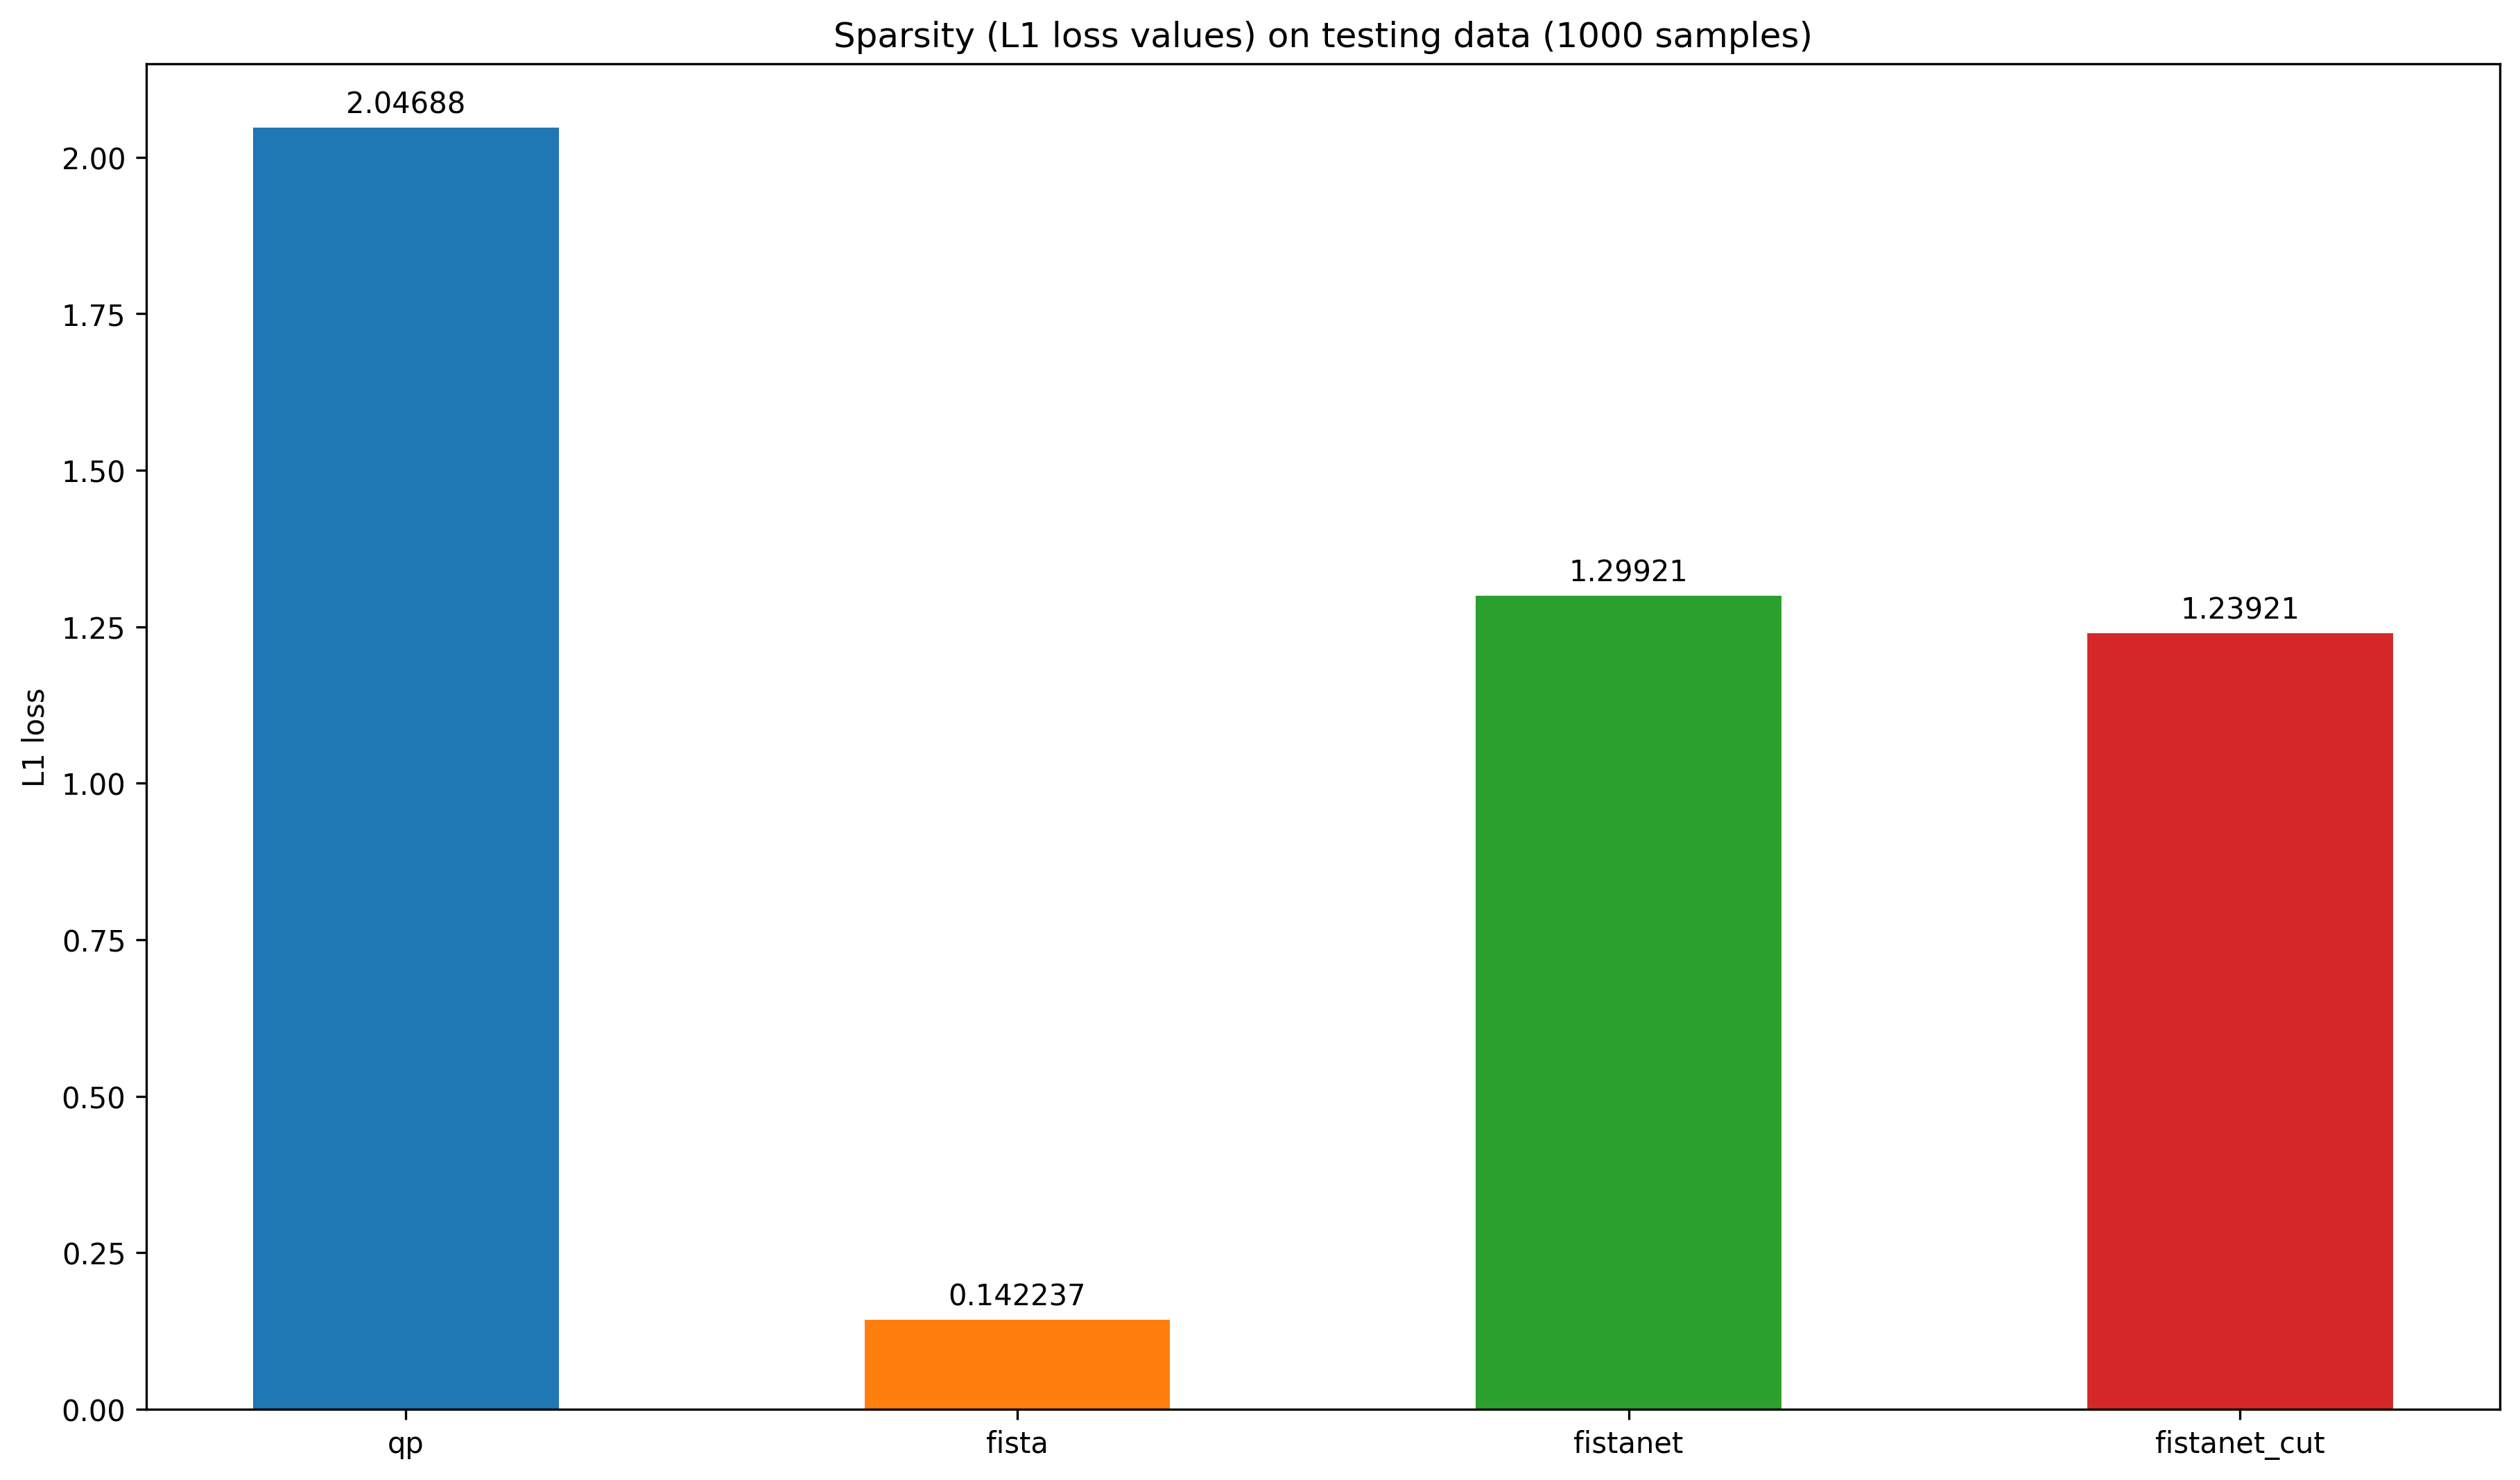

In [113]:
plot_bar_comp(losses_L1, 'L1 loss', 'Sparsity (L1 loss values) on testing data (1000 samples)')

In [131]:
loss = lambda x: torch.mean(torch.abs(x)).cpu()
losses_L1_norm = {
    'fistanet': loss(max_abs_norm(x_fistanet)),
    'fistanet_cut': loss(max_abs_norm(x_fistanet_cut)),
    'bpdn_maxiter': loss(max_abs_norm(x_bpdn)),
    'bpdn_5iter': loss(max_abs_norm(x_bpdn5)),
    'bpdn_3iter': loss(max_abs_norm(x_bpdn3)),
    'bpdn_1iter': loss(max_abs_norm(x_bpdn1))
}

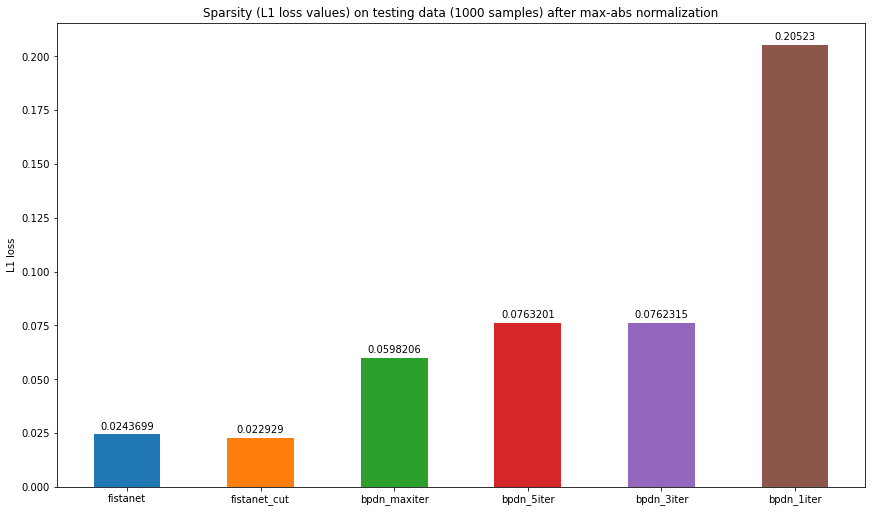

In [132]:
plot_bar_comp(losses_L1_norm, 'L1 loss', 'Sparsity (L1 loss values) on testing data (1000 samples) after max-abs normalization')

## Compare single BW noise approximation examples

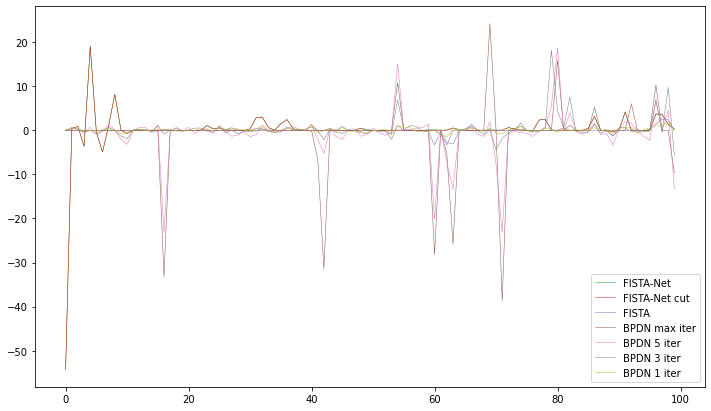

In [73]:
plot_comp_example_alpha(0)

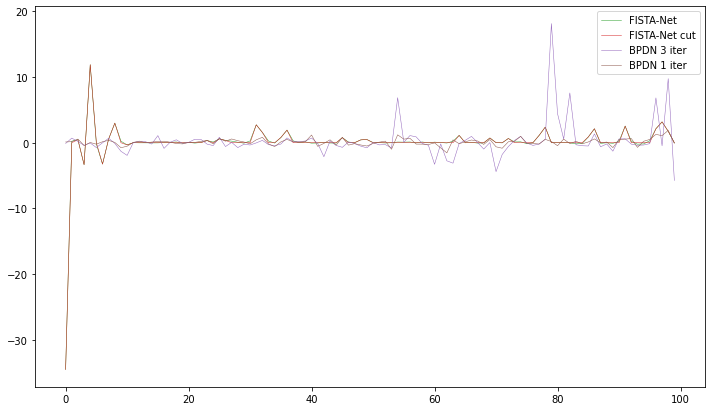

In [134]:
plot_comp_example_alpha(0, [True, False, False, True, True])

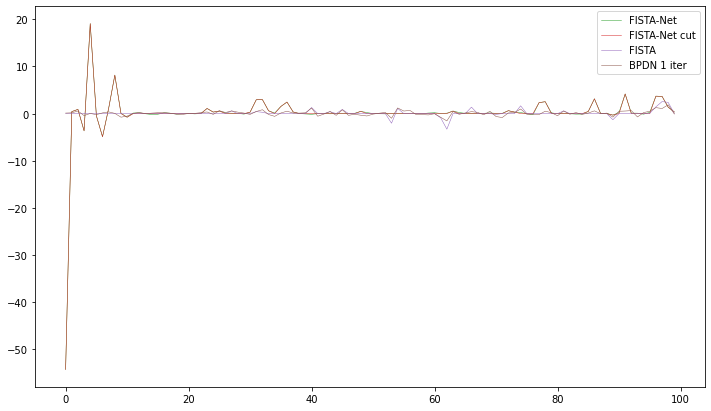

In [74]:
plot_comp_example_alpha(0, [True, False, False, False, True])

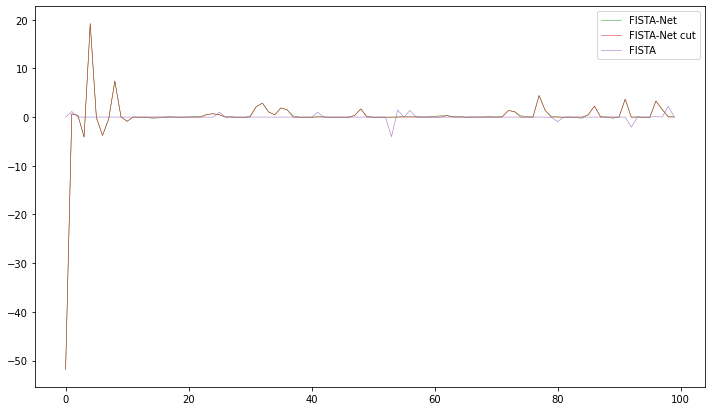

In [75]:
plot_comp_example_alpha(210, [True, False, False, False, False])

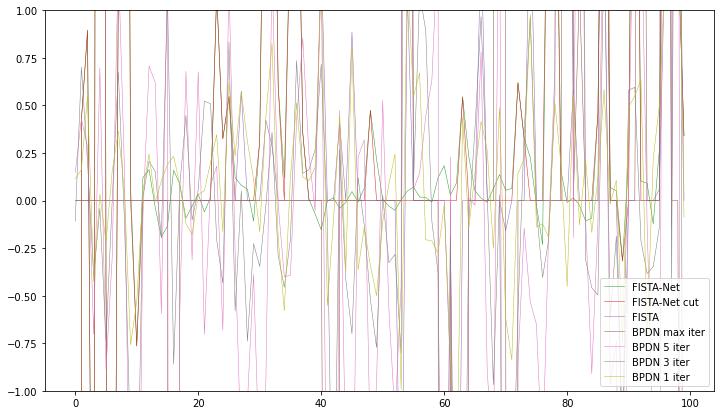

In [76]:
plot_comp_example_alpha(0, ylim=(-1, 1))

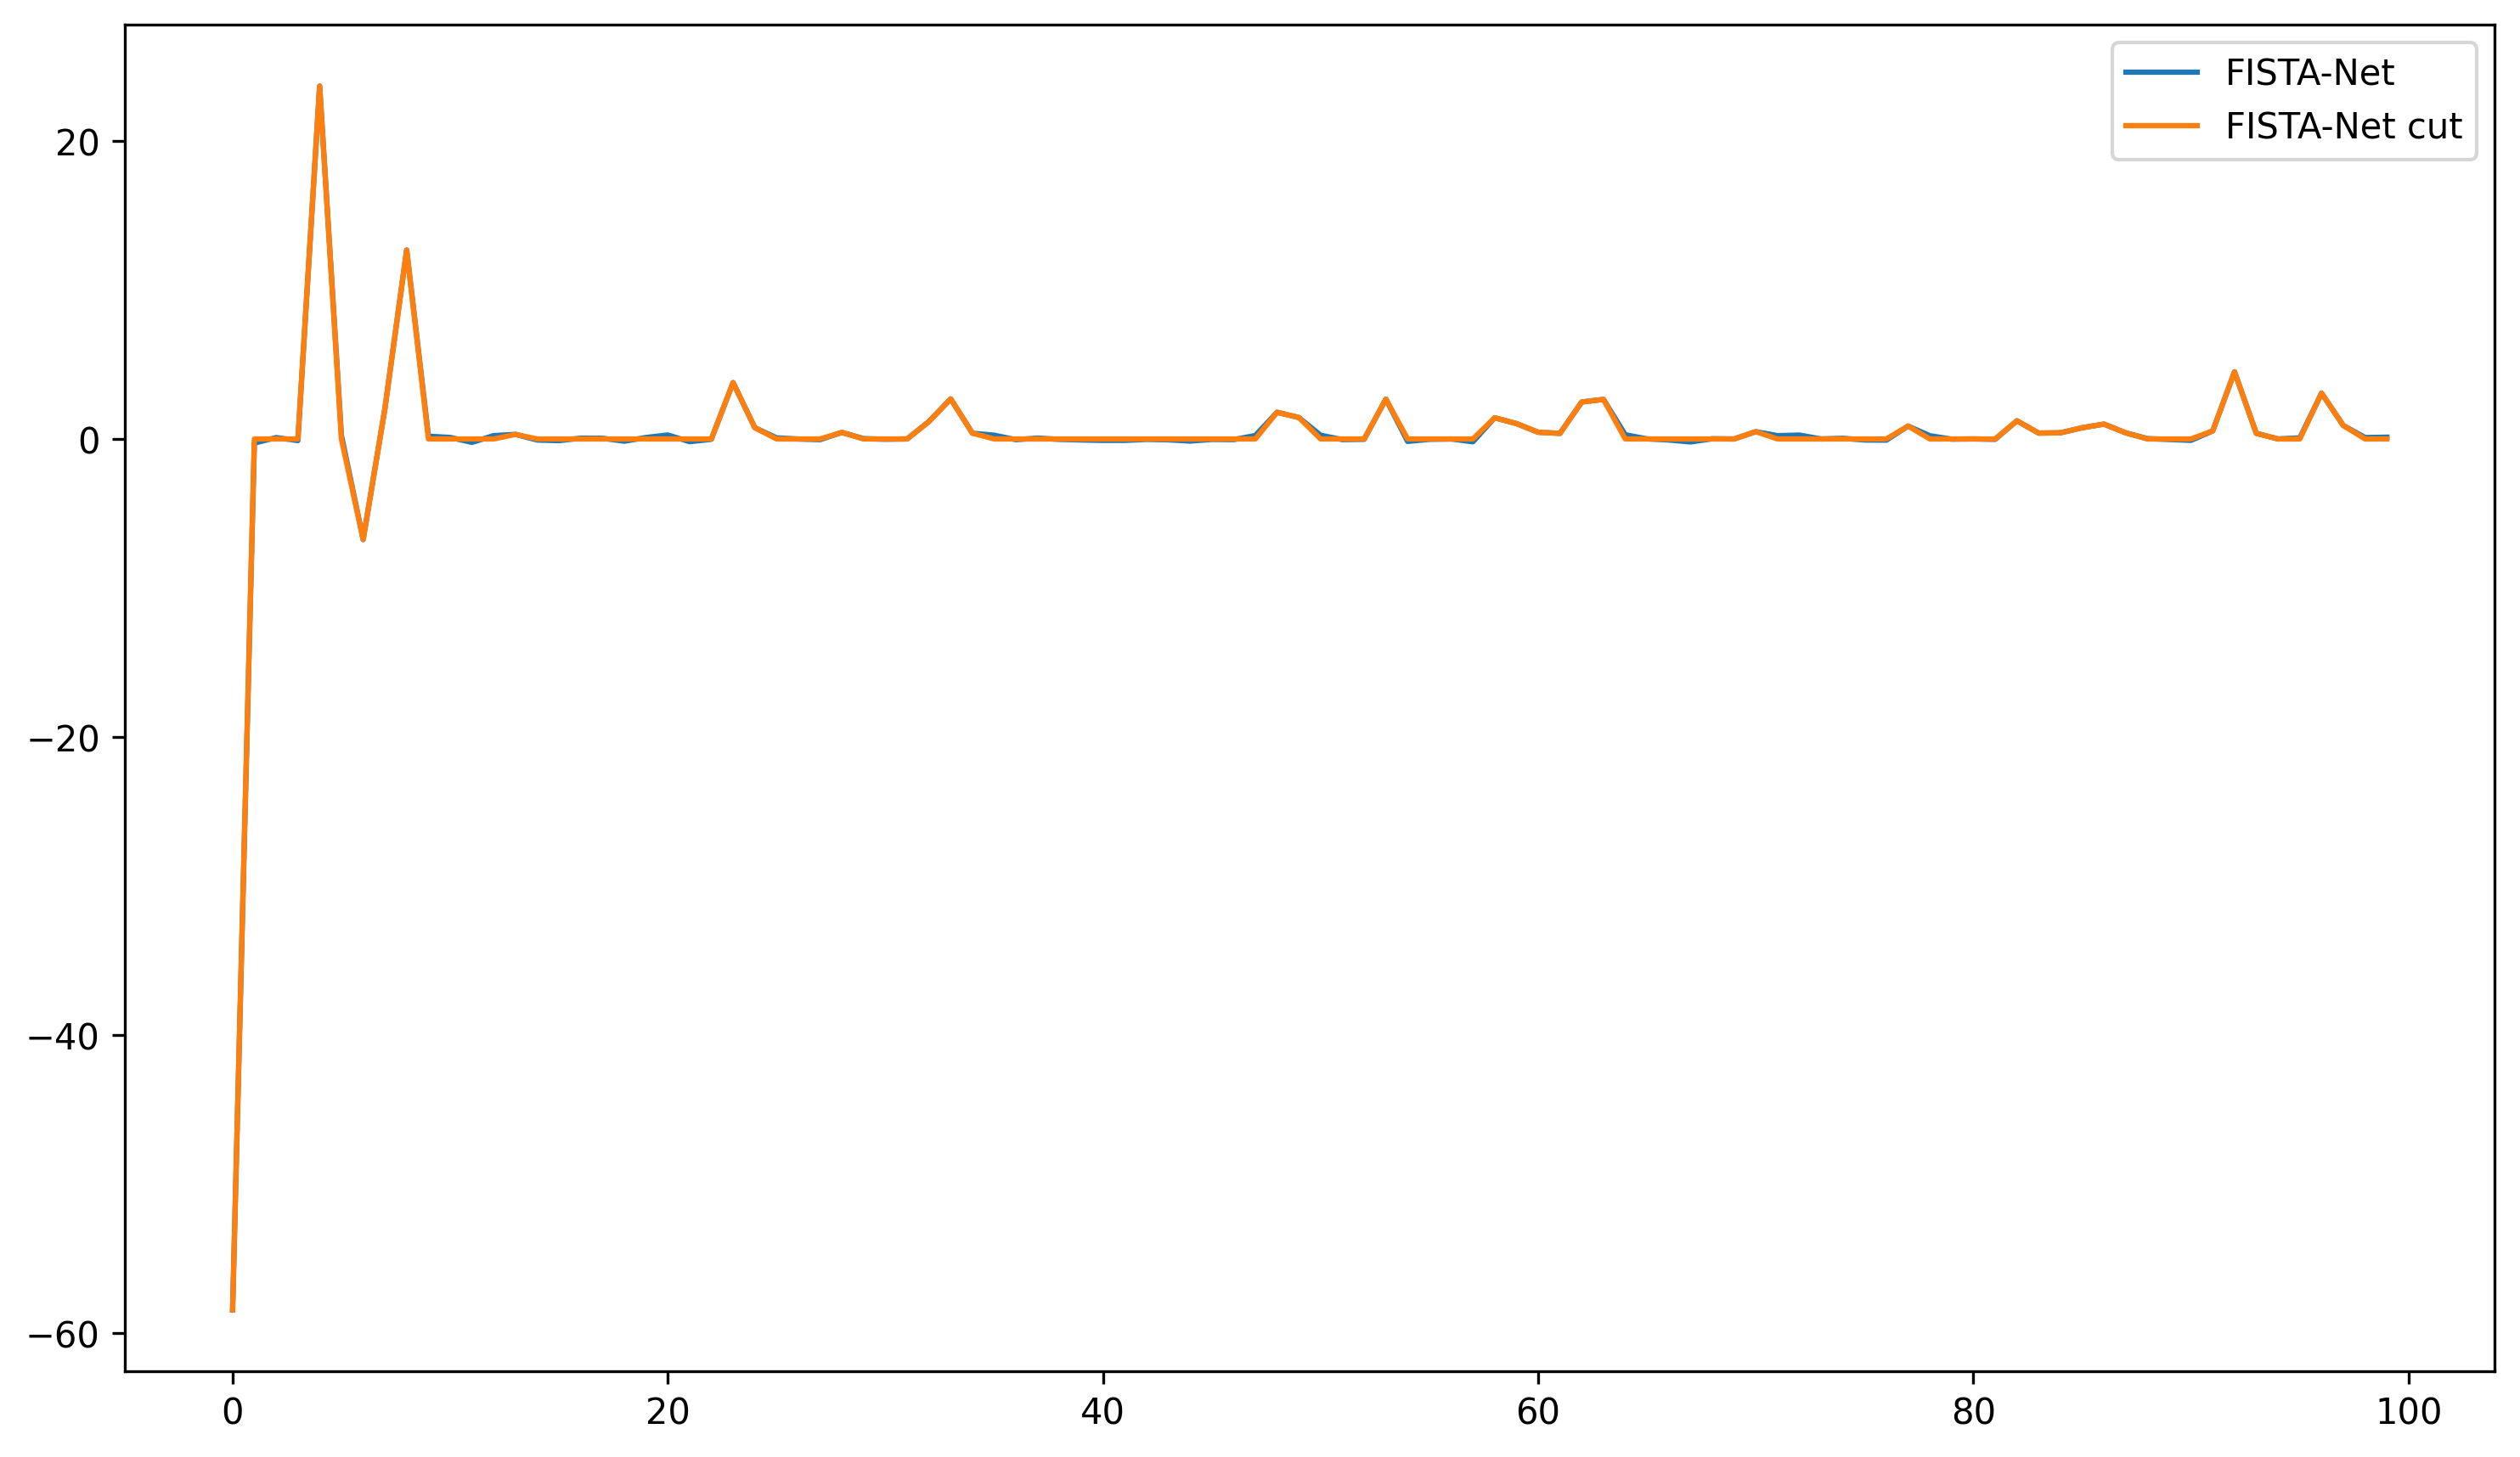

In [133]:
plot_comp_example_alpha(5, [True, False, False, False, False])

## Compare inference times

In [ ]:
print('FISTA-Net GPU (1 batch = 1000 samples):', '1.2129542999999998', 's')  # from solver.test()

FISTA-Net GPU (1 batch = 1000 samples): 1.2129542999999998 s


In [ ]:
lambda_param = 0.001
noisy = x_in[1, :].numpy()
diction = dictionary[0, :, :].numpy()

start = timeit.default_timer()

alpha = BPDN(noisy, diction, lambda_param=lambda_param)[1]

stop = timeit.default_timer()

print('BPDN CPU (1 sample):', stop - start, 's') 

BPDN CPU (1 sample): 12.018897300004028 s


In [ ]:
max_iters = 5

start = timeit.default_timer()

alpha = BPDN(noisy, diction, lambda_param=lambda_param, max_iters=max_iters)[1]

stop = timeit.default_timer()

print('BPDN CPU (1 sample):', stop - start, 's') 

BPDN CPU (1 sample): 5.832323600014206 s


In [ ]:
max_iters = 3

start = timeit.default_timer()

alpha = BPDN(noisy, diction, lambda_param=lambda_param, max_iters=max_iters)[1]

stop = timeit.default_timer()

print('BPDN CPU (1 sample):', stop - start, 's') 

BPDN CPU (1 sample): 3.877081000013277 s


In [ ]:
max_iters = 1

start = timeit.default_timer()

alpha = BPDN(noisy, diction, lambda_param=lambda_param, max_iters=max_iters)[1]

stop = timeit.default_timer()

print('BPDN CPU (1 sample):', stop - start, 's') 

BPDN CPU (1 sample): 2.0936430000001565 s


In [ ]:
runtimes = {
    'fistanet': 1.2129542999999998,
    'bpdn_maxiter': 12.018897300004028,
    'bpdn_5iter': 5.832323600014206,
    'bpdn_3iter': 3.877081000013277,
    'bpdn_1iter': 2.0936430000001565,
}

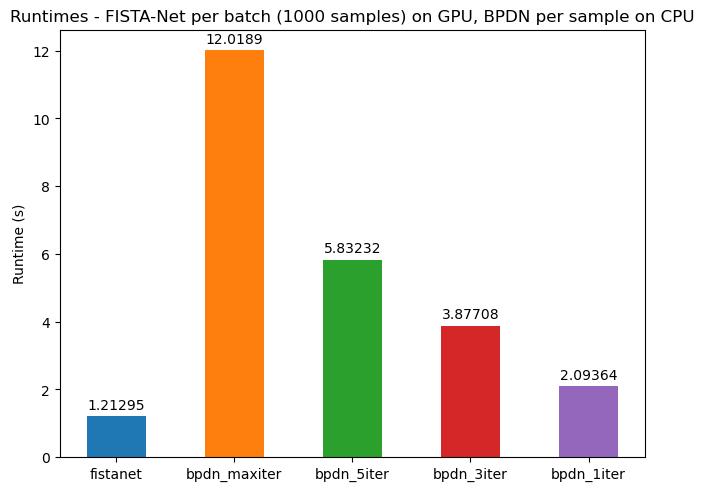

In [ ]:
plot_bar_comp(runtimes, 'Runtime (s)', 'Runtimes - FISTA-Net per batch (1000 samples) on GPU, BPDN per sample on CPU')